  Installing torchdiffeq ...

  PEDIATRIC GROWTH - NEURAL ODE IN Z-SPACE, LAUNCHED AT 24 MONTHS
  train / validate / TEST  ->  forecast + graph + classify
  Device: cpu
  Click 'Choose Files' and select your cohort CSV (e.g. pediatric_cohort_geraedts_who.csv):


Saving pediatric_cohort_geraedts_who.csv to pediatric_cohort_geraedts_who.csv
  Received: pediatric_cohort_geraedts_who.csv  (1,747,570 bytes)
  No Experiment 2 checkpoint found -> retraining the coupled model with the Exp 2 settings
  (upload coupled_growth_ode_v2.pt to skip this step).

  Loading: pediatric_cohort_geraedts_who.csv
  1020 children | 12240 rows | ages [np.float64(0.0), np.float64(1.5), np.float64(3.0), np.float64(6.0), np.float64(9.0), np.float64(12.0), np.float64(18.0), np.float64(24.0), np.float64(30.0), np.float64(36.0), np.float64(48.0), np.float64(60.0)]
  coupling kappa = [np.float64(1.0)]
  Complete trajectories (0-60 m): 1020

  Split by child (seed 42):  train 714 | val 153 | test 153
  Fixed child(ren) [201, 1008] placed in TEST (never trained on).
  LMS reference recovered from training children (largest residual 0.0005 in kg/cm)
  Faltering augmentation: 107 synthetic children added to TRAIN (714 real + 107 synthetic)

--------------------------------------

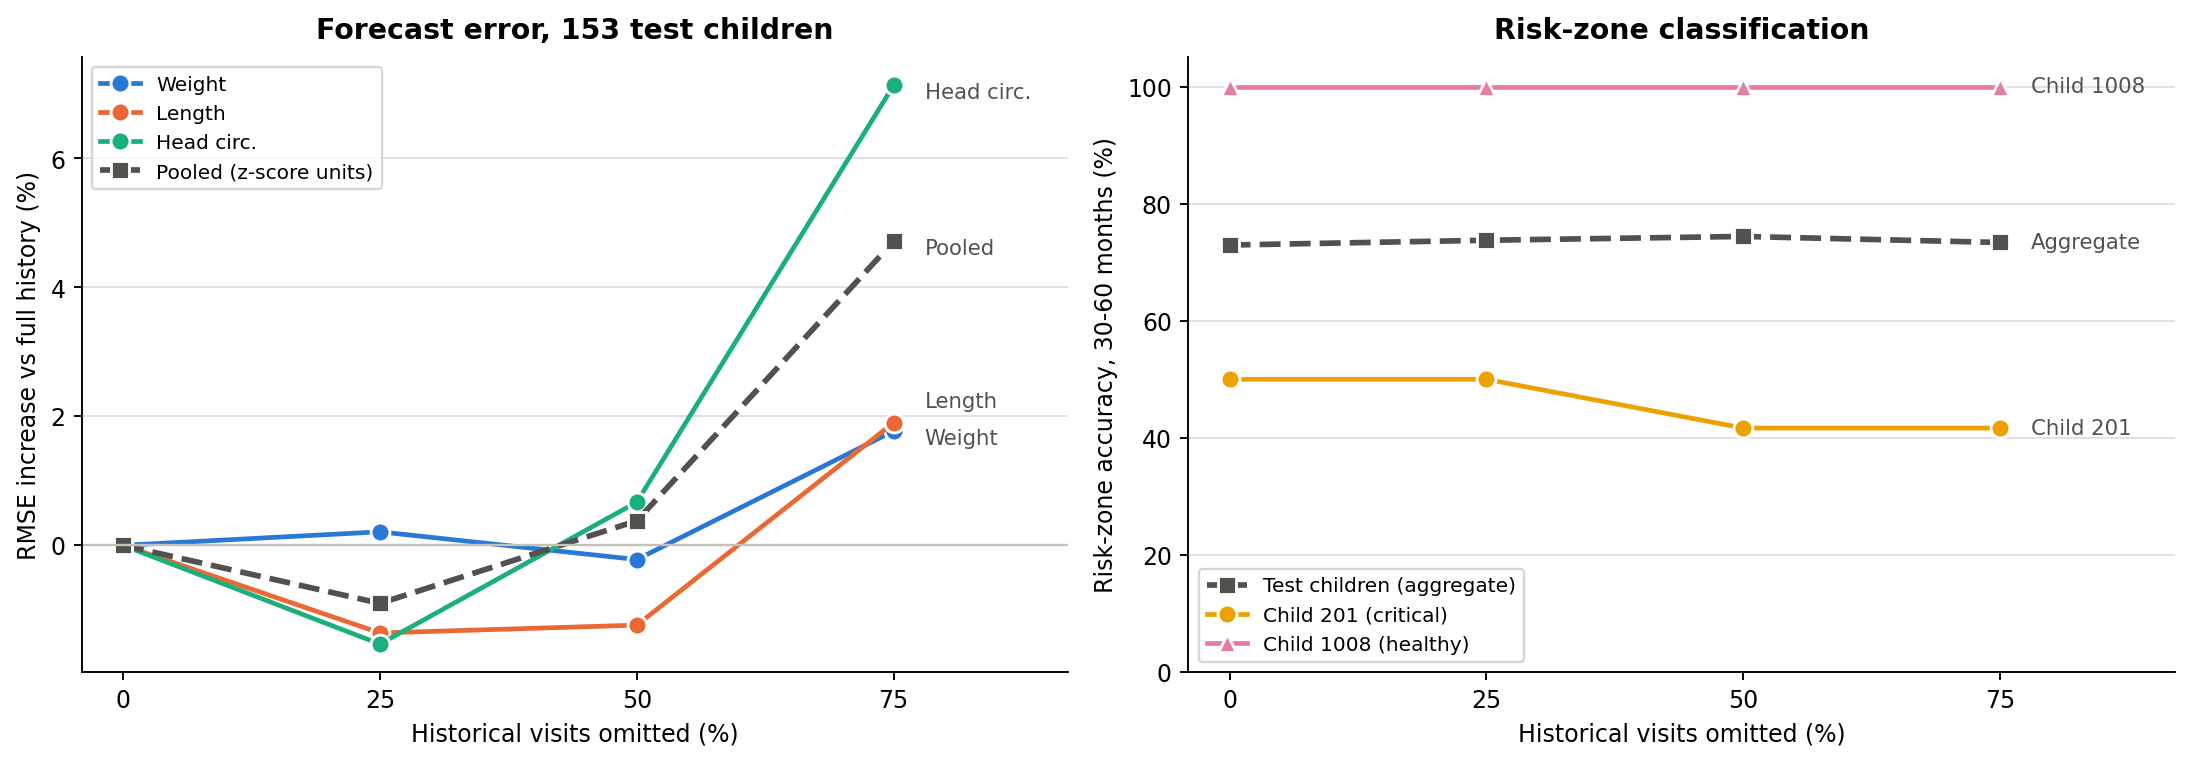

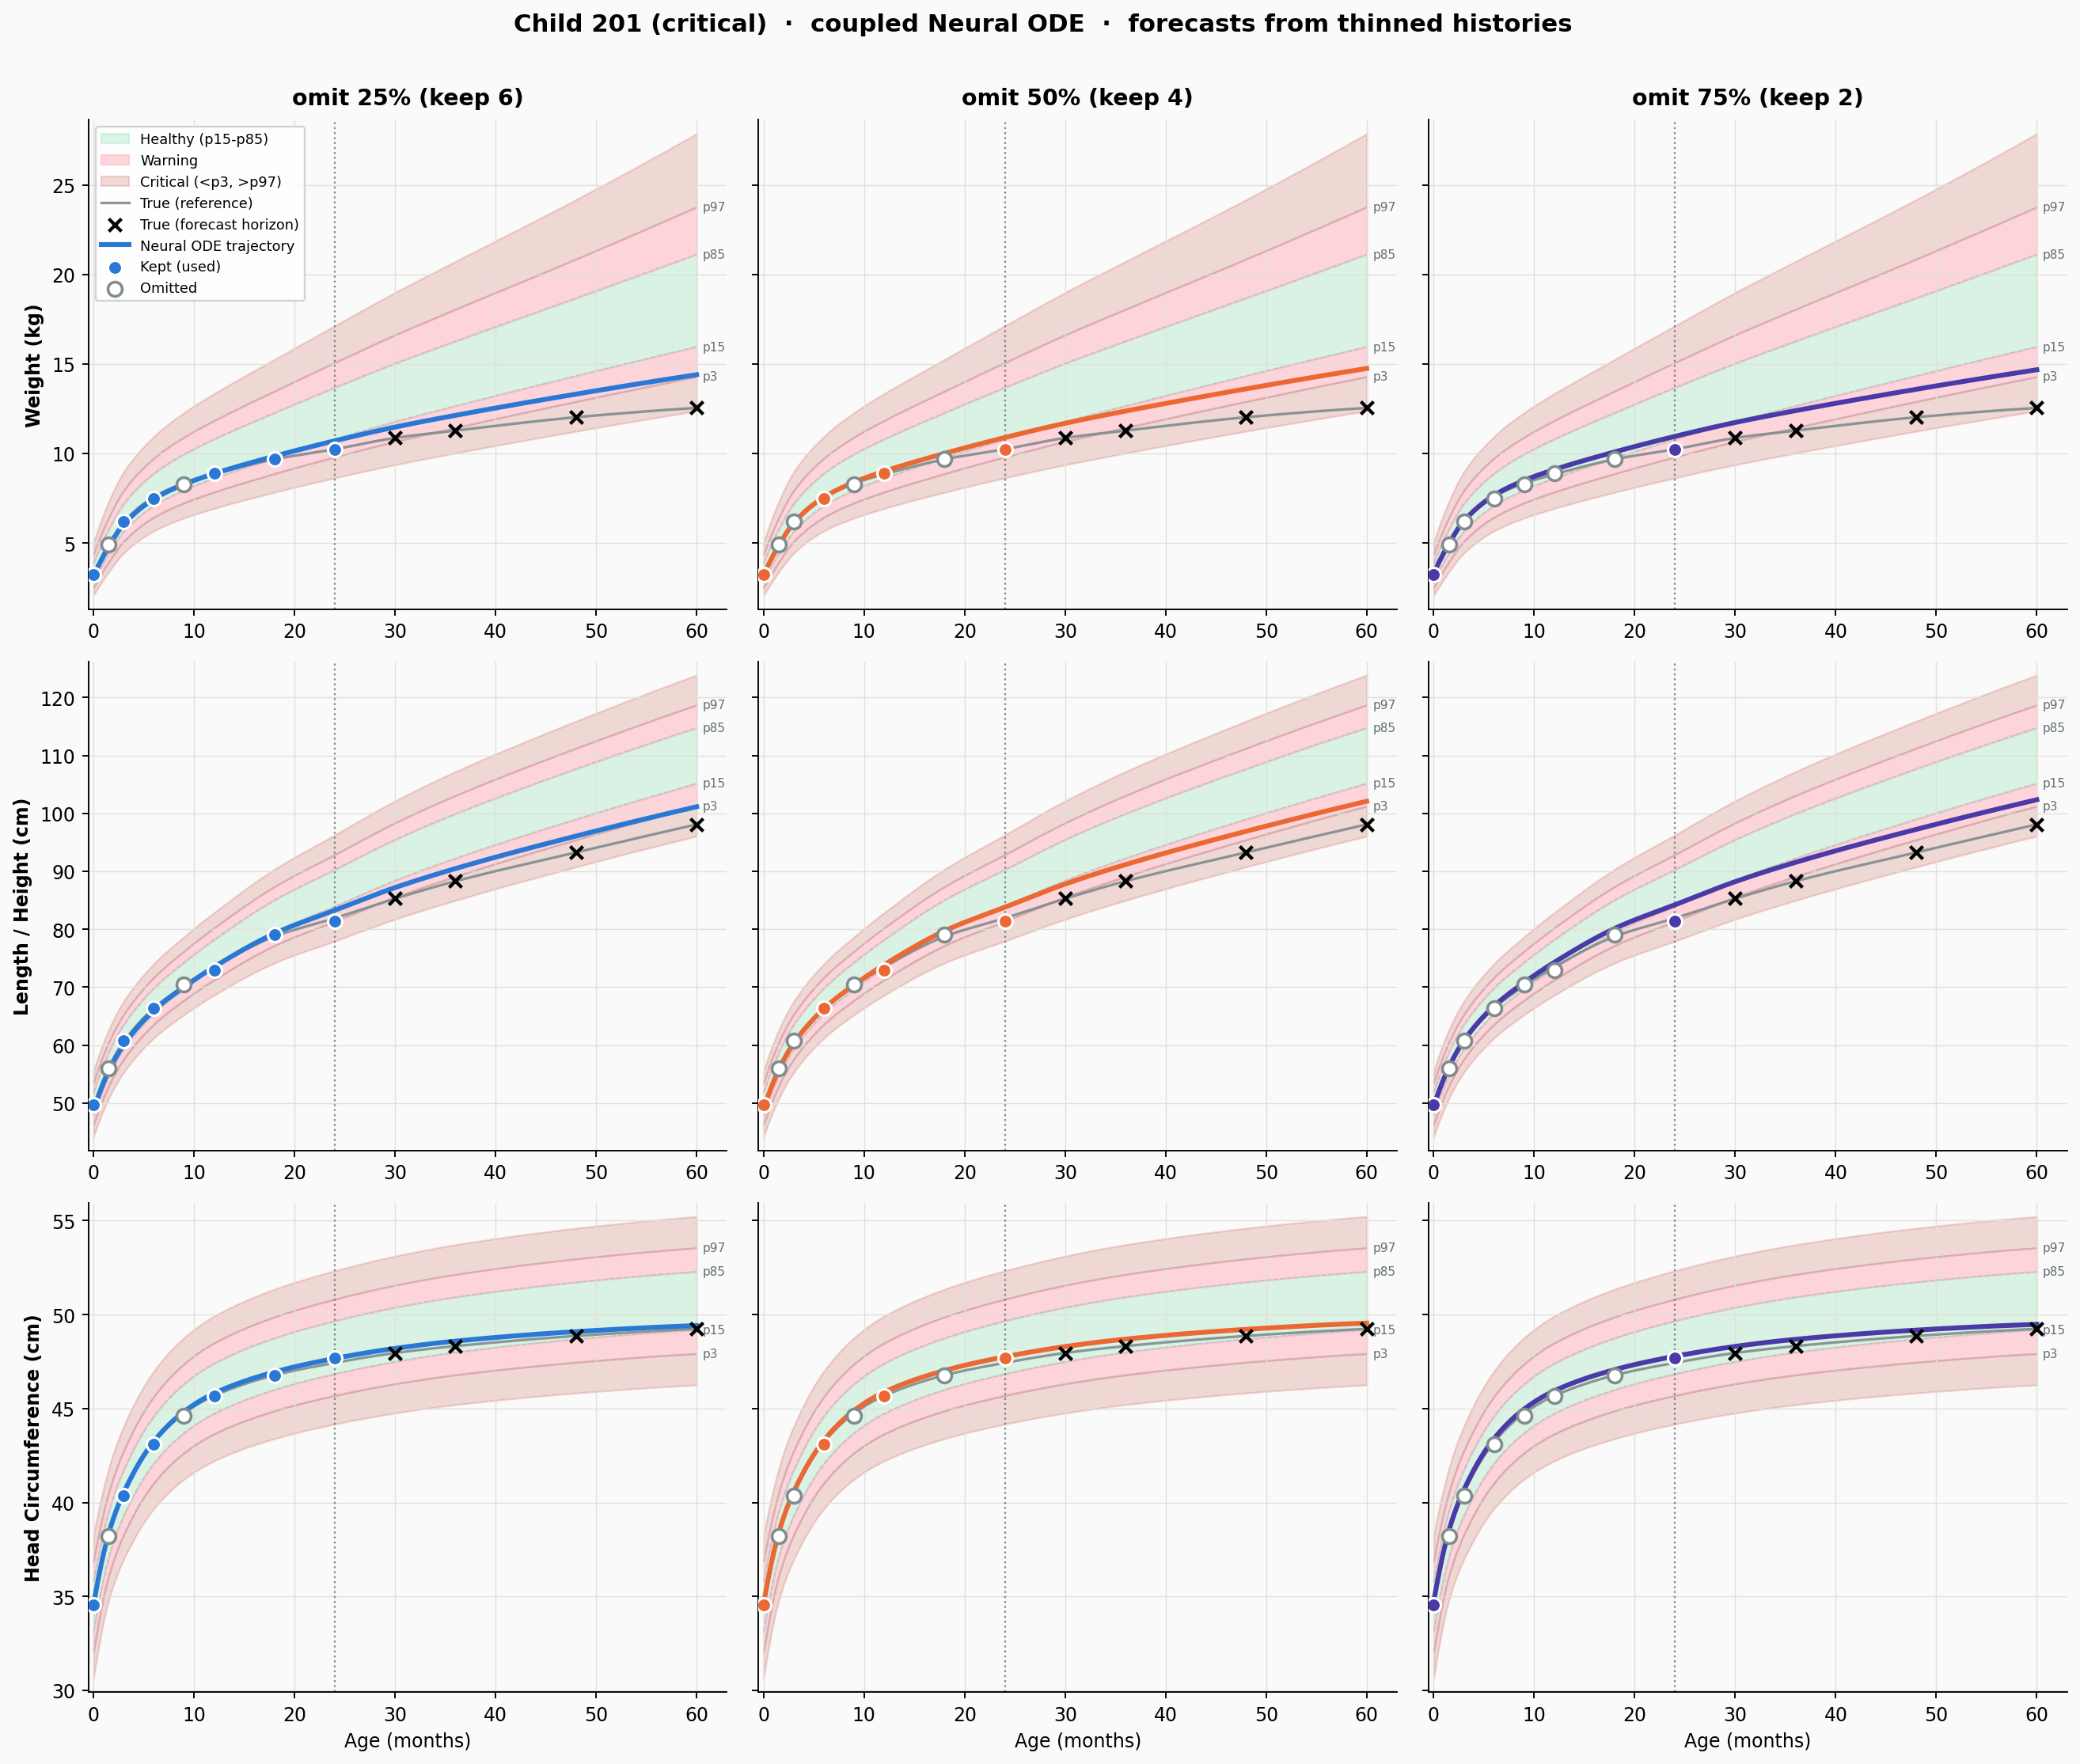

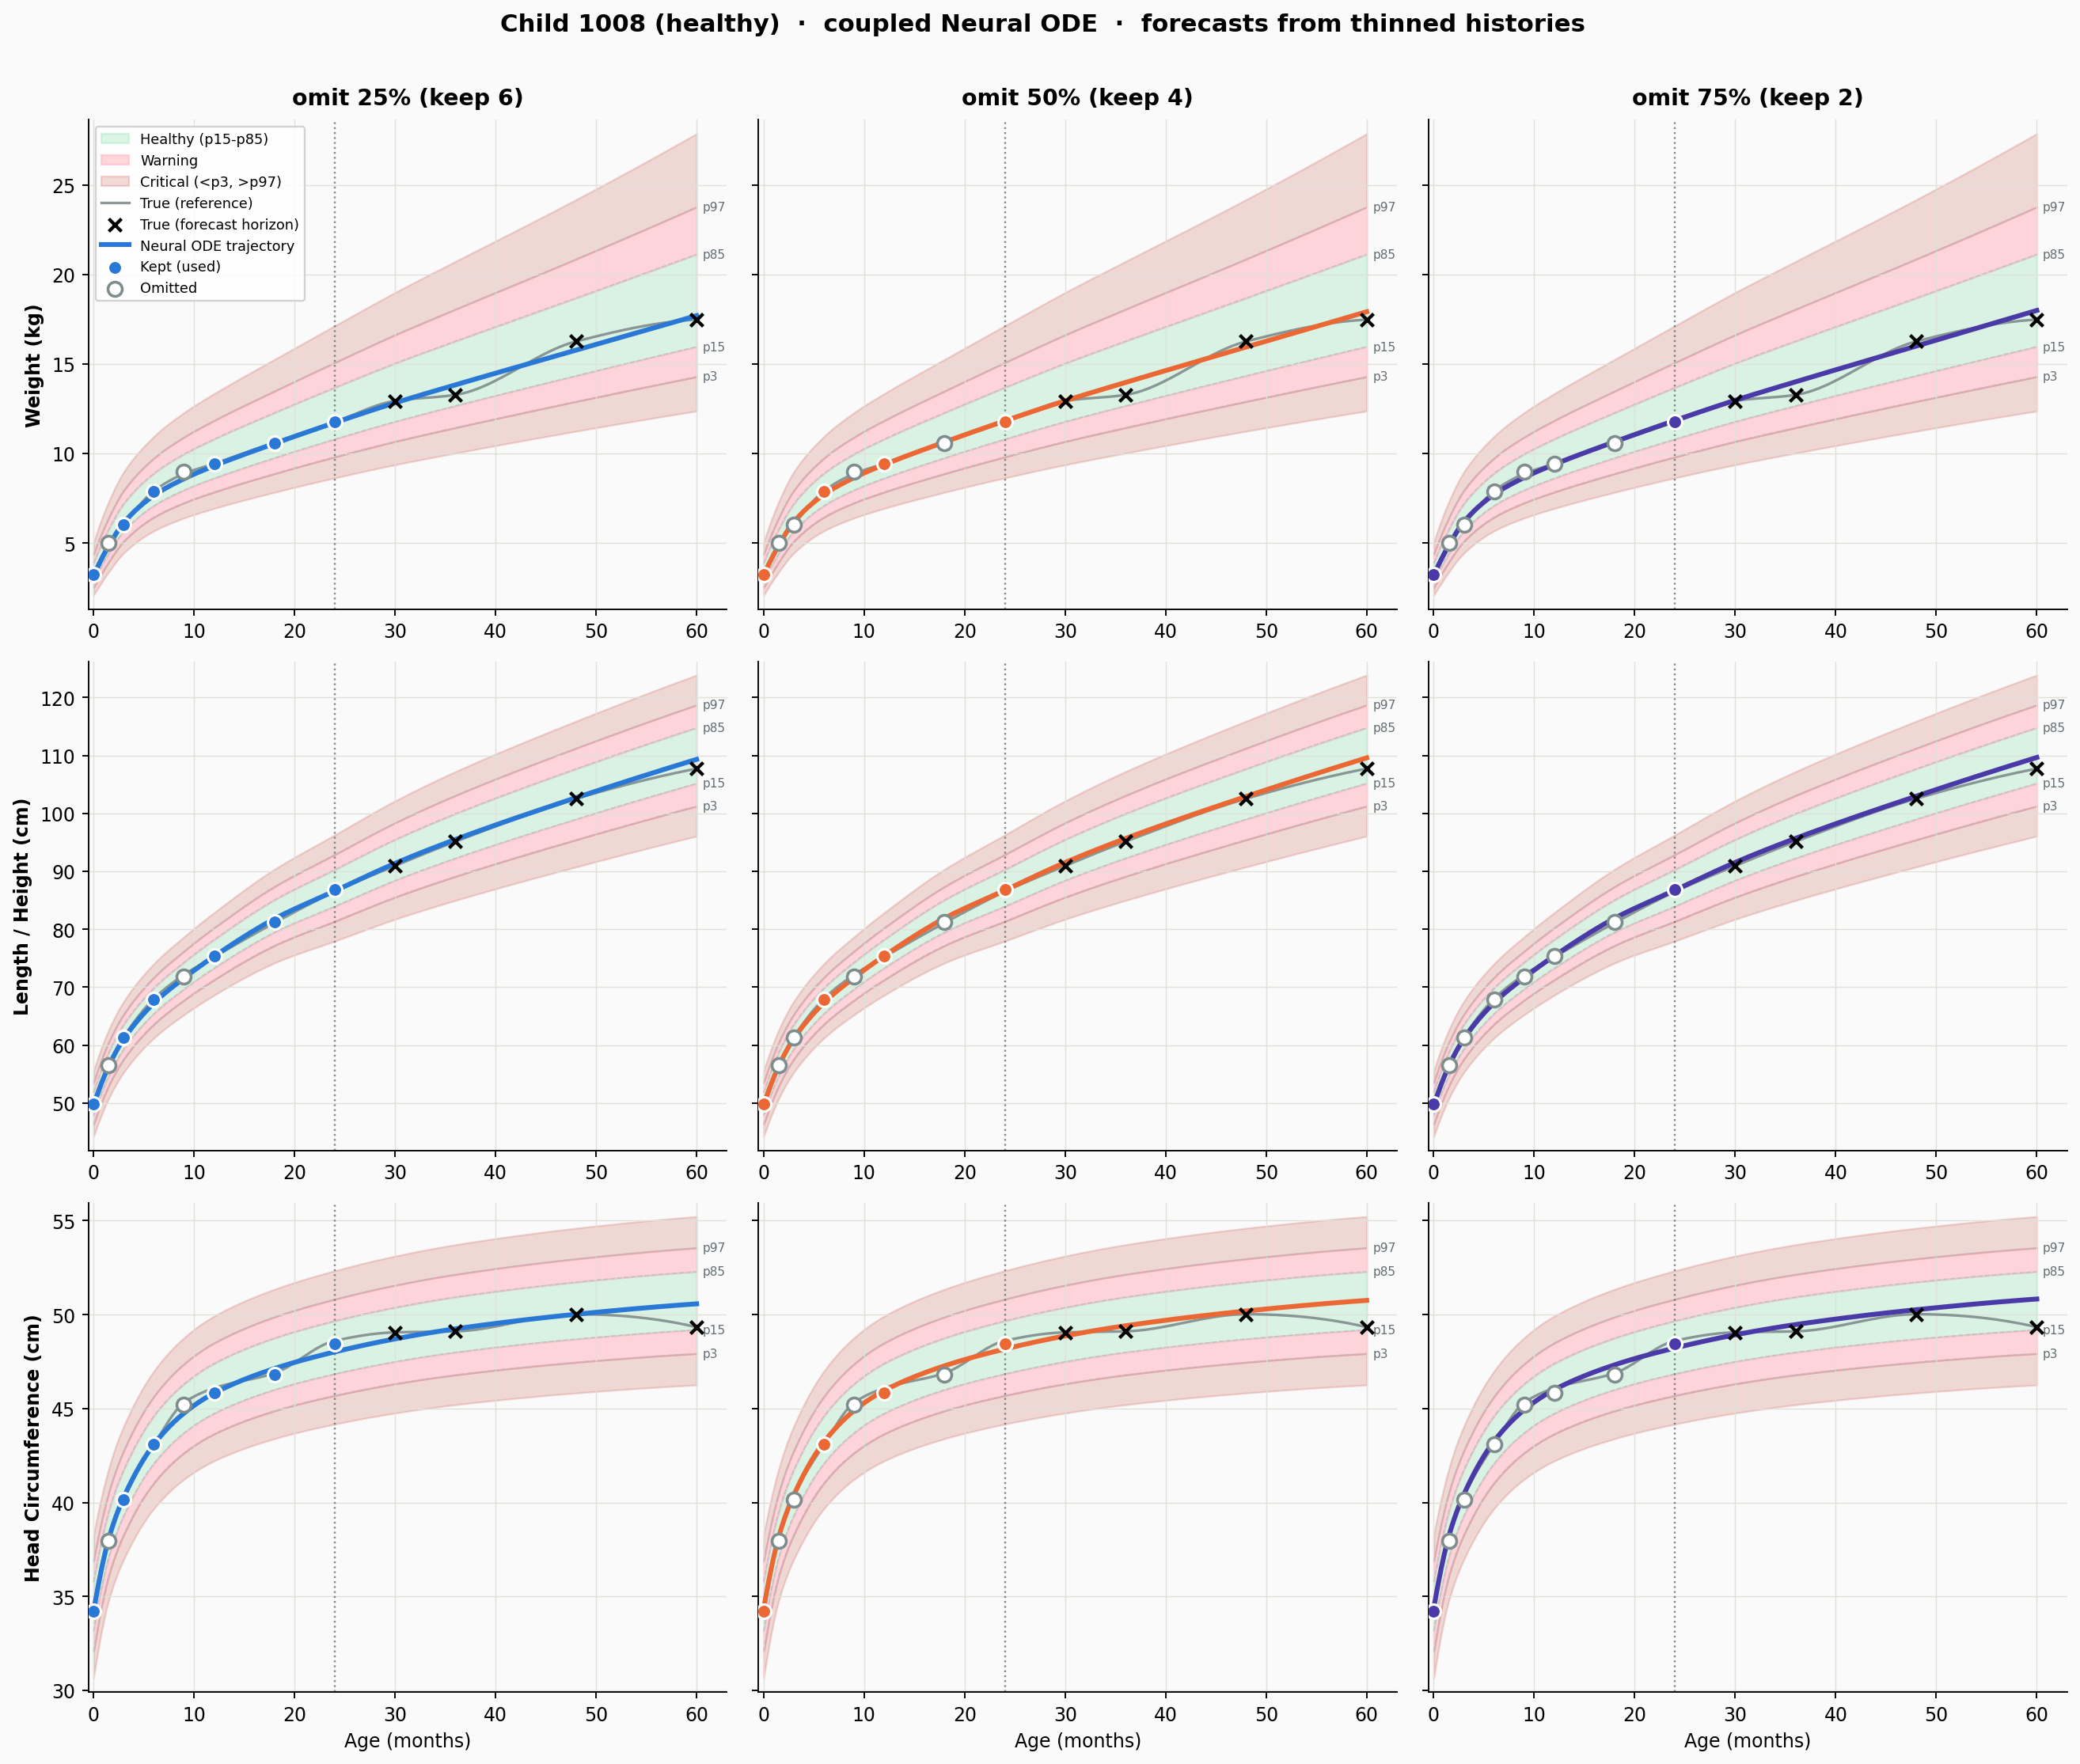

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
"""
Coupled Pediatric Growth Forecasting via a Latent Neural ODE  (version 2)
=========================================================================
Runs on any cohort file with the columns of ``pediatric_cohort_coupled.csv``
(Child_ID, Age_Months, *_true, observed values, z_W / z_L / z_C, Observed).

"""

import os
import sys
import math
import subprocess
import argparse
import warnings

# -- Environment (Colab-aware) -------------------------------------------------
try:
    import google.colab                       # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

try:
    import torchdiffeq                         # noqa: F401
except ImportError:
    print("  Installing torchdiffeq ...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torchdiffeq"],
                   check=False)

import numpy as np
import pandas as pd
import matplotlib
if not IN_COLAB:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator, make_interp_spline
from scipy.optimize import minimize_scalar
from scipy.stats import norm

import torch
import torch.nn as nn
import torch.optim as optim
from torchdiffeq import odeint


def resolve_csv(cfg):
    """In Colab, ALWAYS prompt an upload (so you can see what the model trains on);
    fall back to an existing path only if you cancel the picker."""
    if IN_COLAB:
        from google.colab import files
        print("  Click 'Choose Files' and select your cohort CSV "
              f"(e.g. {cfg['csv_path']}):")
        up = files.upload()
        if up:
            name = list(up.keys())[0]
            print(f"  Received: {name}  ({len(up[name]):,} bytes)")
            return name
        if os.path.exists(cfg["csv_path"]):
            print(f"  No file chosen; falling back to existing {cfg['csv_path']}")
            return cfg["csv_path"]
        raise RuntimeError("No file uploaded and no local CSV found.")
    return cfg["csv_path"]


# ==============================================================================
# 0.  Configuration
# ==============================================================================
CFG = dict(
    csv_path      = "pediatric_cohort_geraedts_who.csv",
    input_signal  = "observed",     # encoder reads this   ("observed" | "true")
    target_signal = "true",         # model reconstructs this ("true" | "observed")
    coupled       = True,           # False -> three independent univariate models
    n_epochs      = 300,
    lr            = 1e-3,
    batch_size    = 128,
    ode_method    = "dopri5",       # "dopri5" (adaptive) or "rk4" (fixed, faster)
    launch        = "encoder",      # "encoder": launch state from the encoded history only
                                    # "last_obs": last observed z-score + learned correction
    forecast_w    = 2.5,            # loss weight on forecast horizons vs history
    beta_nll      = 0.5,            # beta-NLL exponent (0 = plain Gaussian NLL)
    seed          = 42,
    outdir        = ".",
    # ---- split -------------------------------------------------------------
    val_ratio     = 0.15,
    test_ratio    = 0.15,           # train_ratio = 1 - val - test = 0.70
    # ---- FIX 3: probabilistic flagging --------------------------------------
    recall_target = 0.80,           # validation recall the flag thresholds aim for
    # ---- FIX 4: faltering augmentation (training set only) ------------------
    augment_frac  = 0.15,           # synthetic faltering children / real training children
    falter_rate   = (0.02, 0.06),   # drift in z-score units per month
    falter_onset  = (3.0, 15.0),    # drift onset age (months), inside the history window
    falter_cap    = 3.0,            # maximum total drift (z-score units)
    falter_up_frac= 0.20,           # share of synthetic children drifting upward
    # ---- illustrative children ----------------------------------------------
    child_id      = 201,            # critical child, forced into TEST
    typical_child = 1008,           # healthy child, forced into TEST ("auto" | a Child_ID | None)
    experiment_tag= "E2_coupled_v2",
    custom_child  = None,           # dict {age: [W,L,C]} over 0-24 m (birth required)
    # ---- Experiment 3: partial history ------------------------------------------
    partial_history = True,         # True -> run Experiment 3 instead of training
    ckpt_path     = None,           # Exp 2 checkpoint; None -> search the usual places
    retrain       = False,          # True -> always train Exp 2 here, never load a checkpoint
)

# Zone cut-offs in z-space (the p15/p85 and p3/p97 bands):
Z_HEALTHY = 1.0364          # Phi^-1(0.85)
Z_WARNING = 1.8808          # Phi^-1(0.97)
Z90       = 1.6449          # half-width of a 90% Gaussian interval
ZONES     = ["Healthy", "Warning", "Critical"]

ZONE_COLORS = {"Healthy": "#27ae60", "Warning": "#e67e22", "Critical": "#c0392b",
               "Unknown": "#95a5a6"}
STYLE = {
    "bg": "#fafafa", "hist_line": "#2c3e50", "pred_line": "#8e44ad",
    "band_green": "#2ecc71", "band_warn": "#ffb6c1", "band_crit": "#c0392b",
    "grid": "#dfe6e9", "vline": "#636e72",
}


# ==============================================================================
# 1.  Task grid
# ==============================================================================
OBS_AGES      = [0, 1.5, 3, 6, 9, 12, 18, 24]     # historical (encoder) window
FORECAST_AGES = [30, 36, 48, 60]                  # supervised + reported horizons
ALL_AGES      = sorted(set(OBS_AGES + FORECAST_AGES))
TSCALE        = 60.0
LATENT_DIM    = 32
N_VARS        = 3

OBS_IDX   = [ALL_AGES.index(a) for a in OBS_AGES]
FUT_IDX   = [ALL_AGES.index(a) for a in FORECAST_AGES]
LAUNCH    = OBS_AGES[-1]                                   # 24 m
FWD_AGES  = [LAUNCH] + FORECAST_AGES                       # 24 -> 60
BWD_AGES  = [LAUNCH] + OBS_AGES[-2::-1]                    # 24 -> 0
OBS_TNORM = torch.tensor([a / TSCALE for a in OBS_AGES], dtype=torch.float32)
T_FWD     = torch.tensor([a / TSCALE for a in FWD_AGES], dtype=torch.float32)
T_BWD     = torch.tensor([a / TSCALE for a in BWD_AGES], dtype=torch.float32)

TRUE_COLS = ["Weight_kg_true", "Length_cm_true", "HeadCircumference_cm_true"]
OBS_COLS  = ["Weight_kg", "Length_cm", "HeadCircumference_cm"]
Z_COLS    = ["z_W", "z_L", "z_C"]
VLABELS   = ["W", "L", "HC"]


# ==============================================================================
# 2.  FIX 1 -- LMS reference recovered from the cohort; value <-> z-score
# ==============================================================================
def _to_z(x, M, S, L):
    tiny = np.abs(L) < 1e-4
    Ls = np.where(tiny, 1.0, L)
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(tiny, np.log(x / M) / S, ((x / M) ** Ls - 1.0) / (Ls * S))


def _from_z(z, M, S, L):
    tiny = np.abs(L) < 1e-4
    Ls = np.where(tiny, 1.0, L)
    base = np.clip(1.0 + Ls * S * z, 1e-6, None)
    return np.where(tiny, M * np.exp(S * z), M * base ** (1.0 / Ls))


class LMS:
    """Reference median M, coefficient of variation S and Box-Cox power L per
    variable, tabulated at the visit ages and interpolated between them."""
    def __init__(self, M, S, L):
        self.M, self.S, self.L = M, S, L                      # each (12, 3)
        ages = np.array(ALL_AGES, float)
        self._f = [PchipInterpolator(ages, a, axis=0) for a in (M, S, L)]

    def at(self, ages):
        ages = np.asarray(ages, float)
        return tuple(f(ages) for f in self._f)                # each (T, 3)

    def to_z(self, x, ages=ALL_AGES):
        return _to_z(x, *self.at(ages))

    def from_z(self, z, ages=ALL_AGES):
        return _from_z(z, *self.at(ages))


def recover_lms(raw_true, z_true):
    """At each age x^L is linear in z:  x^L = M^L + M^L * L * S * z.
    L is searched per age, so a constant power and the age-varying WHO power
    are both handled.  raw_true, z_true : (N, 12, 3) for TRAINING children."""
    def fit(z, x, L):
        slope, icpt = np.polyfit(z, x ** L, 1)
        M, S = icpt ** (1.0 / L), slope / (icpt * L)
        return M, S, np.abs(_from_z(z, M, S, np.asarray(L)) - x).max()

    T = raw_true.shape[1]
    M, S, L = (np.zeros((T, N_VARS)) for _ in range(3))
    worst = 0.0
    for a in range(T):
        for v in range(N_VARS):
            z, x = z_true[:, a, v].astype(float), raw_true[:, a, v].astype(float)
            best = min((minimize_scalar(lambda p: fit(z, x, p)[2], bounds=b, method="bounded")
                        for b in ((-1.5, -1e-3), (1e-3, 2.0))), key=lambda r: r.fun)
            Lv = float(np.round(best.x, 3)) or 1e-3
            M[a, v], S[a, v], resid = fit(z, x, Lv)
            L[a, v] = Lv
            worst = max(worst, resid)
    print(f"  LMS reference recovered from training children "
          f"(largest residual {worst:.4f} in kg/cm)")
    if worst > 0.05:
        warnings.warn("LMS recovery residual is large; check the z-score columns.")
    return LMS(M, S, L)


def zone_idx(z):
    a = np.abs(z)
    return (a > Z_HEALTHY).astype(int) + (a > Z_WARNING).astype(int)


def overall_zone(zones):
    return max(zones, key=lambda z: ZONES.index(z))


# ==============================================================================
# 3.  Model -- Bi-GRU encoder, FIX 2 launch at 24 m, FIX 3 uncertainty head
# ==============================================================================
class TrajectoryEncoder(nn.Module):
    """Bi-GRU over [(z-scores, t_norm, mask) x T_obs] -> child context, plus a
    learned correction to the launch state (zero at initialisation)."""
    def __init__(self, n_vars=N_VARS, hidden_dim=64, latent_dim=LATENT_DIM):
        super().__init__()
        self.gru  = nn.GRU(n_vars + 2, hidden_dim, batch_first=True, bidirectional=True)
        self.proj = nn.Sequential(nn.Linear(hidden_dim * 2, latent_dim), nn.Tanh())
        self.launch = nn.Linear(latent_dim, n_vars)
        nn.init.zeros_(self.launch.weight)
        nn.init.zeros_(self.launch.bias)

    def forward(self, seq):
        _, h = self.gru(seq)
        ctx = self.proj(torch.cat([h[0], h[1]], dim=-1))
        return ctx, self.launch(ctx)


class ConditionedODEFunc(nn.Module):
    """dz/dt = f_theta(z, t, ctx).  With n_vars = 3 the variables are coupled
    through shared weights; with n_vars = 1 the model is univariate."""
    def __init__(self, state_dim=N_VARS, latent_dim=LATENT_DIM, hidden_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim + 1 + latent_dim, hidden_dim), nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.SiLU(),
            nn.Linear(hidden_dim, state_dim),
        )
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight, gain=0.1)
                nn.init.zeros_(m.bias)
        self._ctx = None

    def set_context(self, ctx):
        self._ctx = ctx

    def forward(self, t, h):
        return self.net(torch.cat([h, t.expand(h.shape[0], 1), self._ctx], dim=1))


class SigmaHead(nn.Module):
    """log sigma(t | ctx) per variable: the predictive standard deviation."""
    def __init__(self, n_vars=N_VARS, latent_dim=LATENT_DIM, hidden_dim=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(latent_dim + 1, hidden_dim), nn.SiLU(),
                                 nn.Linear(hidden_dim, n_vars))
        nn.init.constant_(self.net[-1].bias, math.log(0.3))

    def forward(self, ctx, t_norm):
        B, T = ctx.shape[0], t_norm.shape[0]
        x = torch.cat([ctx[:, None, :].expand(B, T, -1),
                       t_norm.view(1, T, 1).expand(B, T, 1)], dim=-1)
        return self.net(x).clamp(-4.0, 1.5)


class LatentGrowthODE(nn.Module):
    def __init__(self, n_vars=N_VARS, hidden_enc=64, hidden_ode=128,
                 latent_dim=LATENT_DIM, method="dopri5", launch="encoder"):
        super().__init__()
        self.encoder  = TrajectoryEncoder(n_vars, hidden_enc, latent_dim)
        self.ode_func = ConditionedODEFunc(n_vars, latent_dim, hidden_ode)
        self.sigma    = SigmaHead(n_vars, latent_dim)
        self.method   = method
        self.launch   = launch
        if launch == "encoder":
            # launch state z(24 m) read off the encoded history alone
            self.state_head = nn.Sequential(nn.Linear(latent_dim, 64), nn.SiLU(),
                                            nn.Linear(64, n_vars))

    def _flow(self, h0, t, rtol=1e-4, atol=1e-5):
        if self.method == "rk4":
            out = odeint(self.ode_func, h0, t, method="rk4",
                         options=dict(step_size=1.0 / 60.0))
        else:
            out = odeint(self.ode_func, h0, t, method=self.method, rtol=rtol, atol=atol)
        return out.permute(1, 0, 2)                       # (B, T, n_vars)

    def predict_grid(self, seq, z_last, t_fwd, t_bwd):
        """Launch at t_fwd[0] = t_bwd[0] (24 m) and integrate forward and
        backward in time.  launch="encoder": the launch state comes from the
        encoded history only (z_last is ignored); launch="last_obs": last
        observed z-score plus a learned correction.
        Returns mean_fwd, mean_bwd, log_sigma_fwd, log_sigma_bwd."""
        ctx, corr = self.encoder(seq)
        h0 = self.state_head(ctx) if self.launch == "encoder" else z_last + corr
        self.ode_func.set_context(ctx)
        return (self._flow(h0, t_fwd), self._flow(h0, t_bwd),
                self.sigma(ctx, t_fwd), self.sigma(ctx, t_bwd))


class IndependentGrowthODE(nn.Module):
    """Three univariate models with no shared information (matched baseline)."""
    def __init__(self, **kw):
        super().__init__()
        self.models = nn.ModuleList([LatentGrowthODE(n_vars=1, **kw) for _ in range(N_VARS)])

    def predict_grid(self, seq, z_last, t_fwd, t_bwd):
        outs = [m.predict_grid(seq[..., [v, N_VARS, N_VARS + 1]], z_last[:, [v]], t_fwd, t_bwd)
                for v, m in enumerate(self.models)]
        return tuple(torch.cat([o[k] for o in outs], dim=-1) for k in range(4))


def build_model(cfg):
    kw = dict(method=cfg["ode_method"], launch=cfg.get("launch", "last_obs"))
    return LatentGrowthODE(**kw) if cfg["coupled"] else IndependentGrowthODE(**kw)


def on_visit_grid(model, seq, z_last, device):
    """Mean and log-sigma on ALL_AGES, shape (B, 12, 3)."""
    mf, mb, lf, lb = model.predict_grid(seq, z_last, T_FWD.to(device), T_BWD.to(device))
    return (torch.cat([mb[:, 1:].flip(1), mf], dim=1),
            torch.cat([lb[:, 1:].flip(1), lf], dim=1))


# ==============================================================================
# 4.  Data pipeline
# ==============================================================================
def load_data(path):
    print(f"\n  Loading: {path}")
    df = pd.read_csv(path) if str(path).lower().endswith((".csv", ".tsv")) \
        else pd.read_excel(path)
    required = set(["Child_ID", "Age_Months", "Observed"] + TRUE_COLS + OBS_COLS + Z_COLS)
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"Missing columns: {missing}")
    print(f"  {df.Child_ID.nunique()} children | {len(df)} rows "
          f"| ages {sorted(df.Age_Months.unique())}")
    if "kappa" in df.columns:
        print(f"  coupling kappa = {sorted(df.kappa.unique())}")
    return df


def build_arrays(df):
    """For every child with the full 0-60 m grid:
        z_true (N,12,3)  raw_true (N,12,3)  raw_obs (N,12,3, NaN = missed)
        mask (N,12)  ids (N,)."""
    zs, trues, obss, masks, ids = [], [], [], [], []
    for cid, g in df.groupby("Child_ID"):
        g = g.drop_duplicates("Age_Months").set_index("Age_Months")
        if not all(a in g.index for a in ALL_AGES):
            continue
        zs.append(g.loc[ALL_AGES, Z_COLS].values.astype(np.float32))
        trues.append(g.loc[ALL_AGES, TRUE_COLS].values.astype(np.float32))
        obss.append(g.loc[ALL_AGES, OBS_COLS].values.astype(np.float32))
        masks.append(g.loc[ALL_AGES, "Observed"].astype(float).values.astype(np.float32))
        ids.append(cid)
    print(f"  Complete trajectories (0-60 m): {len(ids)}")
    return dict(z_true=np.stack(zs), raw_true=np.stack(trues), raw_obs=np.stack(obss),
                mask=np.stack(masks), ids=np.array(ids))


def split_indices(ids, cfg):
    """70/15/15 split BY CHILD with the critical child (cfg['child_id']) and the
    healthy child (cfg['typical_child'], when a Child_ID) forced into TEST."""
    N, seed = len(ids), cfg["seed"]
    n_test = int(round(cfg["test_ratio"] * N))
    n_val  = int(round(cfg["val_ratio"] * N))
    perm = list(np.random.default_rng(seed).permutation(N))
    id_to_pos = {int(c): i for i, c in enumerate(ids)}
    forced = []
    if cfg.get("child_id") is not None and int(cfg["child_id"]) in id_to_pos:
        forced = [id_to_pos[int(cfg["child_id"])]]
    rest = [p for p in perm if p not in set(forced)]
    test_idx  = forced + rest[:max(0, n_test - len(forced))]
    remaining = rest[max(0, n_test - len(forced)):]
    # The healthy child must be held out too: swap it into TEST if the random
    # split put it in train/val (no change when it is already in TEST).
    typ = cfg.get("typical_child")
    if isinstance(typ, (int, np.integer)) and int(typ) in id_to_pos:
        tp = id_to_pos[int(typ)]
        if tp not in test_idx and tp in remaining:
            i = remaining.index(tp)
            remaining[i], test_idx[-1] = test_idx[-1], tp
    val_idx, train_idx = remaining[:n_val], remaining[n_val:]
    print(f"\n  Split by child (seed {seed}):  "
          f"train {len(train_idx)} | val {len(val_idx)} | test {len(test_idx)}")
    pinned_ids = [int(c) for c in (cfg.get("child_id"), typ)
                  if isinstance(c, (int, np.integer)) and int(c) in id_to_pos
                  and id_to_pos[int(c)] in test_idx]
    if pinned_ids:
        print(f"  Fixed child(ren) {pinned_ids} placed in TEST (never trained on).")
    return np.array(train_idx), np.array(val_idx), np.array(test_idx)


def make_faltering(z_true, z_obs, mask, n, rng, cfg):
    """FIX 4.  Copy n children and add a sustained drift in z-space:
        drift(t) = sign * rate * max(0, t - onset), capped at falter_cap,
    applied with a per-variable pattern.  Noise and missed visits are kept."""
    src   = rng.integers(0, z_true.shape[0], n)
    ages  = np.array(ALL_AGES, float)
    rate  = rng.uniform(*cfg["falter_rate"], n)
    onset = rng.uniform(*cfg["falter_onset"], n)
    sign  = np.where(rng.random(n) < cfg["falter_up_frac"], 1.0, -1.0)
    patterns = np.array([[1.0, 1.0, 0.3],     # weight + length, head mostly spared
                         [1.0, 0.4, 0.2],     # weight-led
                         [1.0, 1.0, 1.0]])    # all three
    pat = patterns[rng.choice(len(patterns), n, p=[0.5, 0.25, 0.25])]
    ramp = np.clip(ages[None, :] - onset[:, None], 0.0, None) * rate[:, None]
    ramp = np.minimum(ramp, cfg["falter_cap"]) * sign[:, None]            # (n, 12)
    drift = (ramp[:, :, None] * pat[:, None, :]).astype(np.float32)       # (n, 12, 3)
    return z_true[src] + drift, z_obs[src] + drift, mask[src].copy()


def make_pack(z_true, z_obs, mask, ids, lms):
    """Tensors for training plus numpy copies for scoring."""
    N = z_true.shape[0]
    zo = np.nan_to_num(z_obs, nan=0.0).astype(np.float32)
    hist = mask[:, OBS_IDX]
    last = (hist * np.arange(len(OBS_IDX))[None, :]).argmax(axis=1)      # last attended visit
    z_last = zo[np.arange(N), np.array(OBS_IDX)[last]]
    return dict(
        z_true=torch.from_numpy(z_true.astype(np.float32)),
        z_obs=torch.from_numpy(zo),
        mask=torch.from_numpy(mask.astype(np.float32)),
        z_last=torch.from_numpy(z_last),
        ids=np.asarray(ids),
        z_true_np=z_true, z_last_np=z_last,
        raw_true=lms.from_z(z_true), raw_obs=lms.from_z(z_obs),
    )


def make_obs_seq(z_win, mask_win, t_norm):
    """z_win (B,To,3), mask_win (B,To), t_norm (To,) -> (B,To,5)."""
    B, T, _ = z_win.shape
    return torch.cat([z_win, t_norm.view(1, T, 1).expand(B, T, 1),
                      mask_win.view(B, T, 1)], dim=-1)


def encoder_inputs(pack, cfg, device, idx=None):
    sel = slice(None) if idx is None else idx
    if cfg["input_signal"] == "true":
        z, m = pack["z_true"][sel], torch.ones_like(pack["mask"][sel])
        z_last = z[:, OBS_IDX[-1], :]
    else:
        z, m, z_last = pack["z_obs"][sel], pack["mask"][sel], pack["z_last"][sel]
    seq = make_obs_seq(z[:, OBS_IDX, :].to(device), m[:, OBS_IDX].to(device),
                       OBS_TNORM.to(device))
    return seq, z_last.to(device)


# ==============================================================================
# 5.  Training -- masked, forecast-weighted Gaussian negative log-likelihood
# ==============================================================================
def train_model(train, val, cfg, device="cpu"):
    model = build_model(cfg).to(device)
    opt = optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=1e-5)
    sch = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["n_epochs"], eta_min=1e-5)

    w_age = torch.tensor([cfg["forecast_w"] if a in FORECAST_AGES else 1.0
                          for a in ALL_AGES], dtype=torch.float32, device=device)
    w_age = w_age / w_age.mean()
    target_true, beta = (cfg["target_signal"] == "true"), cfg["beta_nll"]

    def loss_on(pack, idx=None):
        sel = slice(None) if idx is None else idx
        seq, z_last = encoder_inputs(pack, cfg, device, idx)
        if target_true:
            tgt = pack["z_true"][sel].to(device)
            tgt_m = torch.ones_like(pack["mask"][sel]).to(device)
        else:
            tgt = pack["z_obs"][sel].to(device)
            tgt_m = pack["mask"][sel].clone().to(device)
            tgt_m[:, FUT_IDX] = 1.0
        mu, ls = on_visit_grid(model, seq, z_last, device)
        var = torch.exp(2.0 * ls)
        nll = 0.5 * (mu - tgt) ** 2 / var + ls
        if beta > 0:
            nll = nll * var.detach() ** beta
        w = w_age.view(1, -1) * tgt_m
        return (nll.mean(-1) * w).sum() / w.sum().clamp_min(1.0)

    N = train["z_true"].shape[0]
    tr_hist, va_hist, best, best_state = [], [], float("inf"), None
    print(f"\n{'-'*70}\n  {'Coupled' if cfg['coupled'] else 'Independent univariate'} "
          f"Neural ODE in z-space  |  input={cfg['input_signal']} "
          f"target={cfg['target_signal']}  |  solver={cfg['ode_method']}  "
          f"|  epochs={cfg['n_epochs']}  |  launch={cfg.get('launch', 'last_obs')}"
          f"\n{'-'*70}")

    for ep in range(1, cfg["n_epochs"] + 1):
        model.train()
        perm = torch.randperm(N)
        run, nb = 0.0, 0
        for s in range(0, N, cfg["batch_size"]):
            loss = loss_on(train, perm[s:s + cfg["batch_size"]])
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); run += loss.item(); nb += 1
        run /= nb; sch.step()

        model.eval()
        with torch.no_grad():
            vl = loss_on(val).item()
        tr_hist.append(run); va_hist.append(vl)
        if vl < best:
            best, best_state = vl, {k: v.clone() for k, v in model.state_dict().items()}
        if ep % 25 == 0 or ep == 1:
            print(f"  Epoch {ep:4d} | train {run:.5f} | val {vl:.5f} "
                  f"| lr {opt.param_groups[0]['lr']:.2e}")

    model.load_state_dict(best_state)
    print(f"\n  Best val loss: {best:.5f}")
    return model, tr_hist, va_hist


# ==============================================================================
# 6.  Inference
# ==============================================================================
def predict_pack(model, pack, cfg, device="cpu"):
    """Predictive mean and standard deviation in z-space, each (N, 12, 3)."""
    model.eval()
    with torch.no_grad():
        seq, z_last = encoder_inputs(pack, cfg, device)
        mu, ls = on_visit_grid(model, seq, z_last, device)
    return mu.cpu().numpy(), np.exp(ls.cpu().numpy())


def zone_probs(mu, sig):
    """P(not Healthy) and P(Critical) under the Gaussian predictive."""
    p_nh = norm.cdf((-Z_HEALTHY - mu) / sig) + norm.sf((Z_HEALTHY - mu) / sig)
    p_c  = norm.cdf((-Z_WARNING - mu) / sig) + norm.sf((Z_WARNING - mu) / sig)
    return p_nh, p_c


def prob_zone(p_nh, p_c, thr):
    """FIX 3 decision rule: Critical if P(Critical) clears its threshold,
    else Warning if P(not Healthy) clears its threshold, else Healthy."""
    return np.where(p_c >= thr["critical"], 2, np.where(p_nh >= thr["nonhealthy"], 1, 0))


def tune_thresholds(model, val, cfg, device="cpu"):
    """Choose both thresholds on VALIDATION forecasts so that the stated share
    of truly Critical (and truly non-Healthy) cases would be flagged."""
    mu, sig = predict_pack(model, val, cfg, device)
    p_nh, p_c = zone_probs(mu[:, FUT_IDX], sig[:, FUT_IDX])
    tz = zone_idx(val["z_true_np"][:, FUT_IDX])
    q = 1.0 - cfg["recall_target"]
    thr = dict(critical=float(np.quantile(p_c[tz == 2], q)) if (tz == 2).any() else 0.5,
               nonhealthy=float(np.quantile(p_nh[tz >= 1], q)) if (tz >= 1).any() else 0.5)
    print(f"\n  Flag thresholds tuned on validation for {cfg['recall_target']:.0%} recall:  "
          f"P(Critical) >= {thr['critical']:.3f},  P(not Healthy) >= {thr['nonhealthy']:.3f}")
    return thr


def predict_child(model, lms, history, cfg, device="cpu"):
    """Forecast one child from its 0-24 m history ({age: [W,L,C]} in kg/cm).
    Returns the dense trajectory in kg/cm with a 90% forecast interval."""
    if 0 not in history:
        raise ValueError("Birth (age 0) measurement is required.")
    bad = [a for a in history if a not in OBS_AGES]
    if bad:
        raise ValueError(f"Ages {bad} are not on the historical grid {OBS_AGES}.")

    raw = np.full((len(OBS_AGES), N_VARS), np.nan)
    for i, a in enumerate(OBS_AGES):
        if a in history:
            raw[i] = history[a]
    mask = (~np.isnan(raw[:, 0])).astype(np.float32)
    z = np.nan_to_num(lms.to_z(raw, OBS_AGES), nan=0.0).astype(np.float32)
    z_last = z[int(np.nonzero(mask)[0][-1])]
    seq = make_obs_seq(torch.tensor(z[None]), torch.tensor(mask[None]), OBS_TNORM).to(device)

    fwd = np.unique(np.concatenate([np.linspace(LAUNCH, 60.0, 145), FORECAST_AGES]))
    bwd = np.linspace(LAUNCH, 0.0, 97)
    model.eval()
    with torch.no_grad():
        mf, mb, lf, lb = model.predict_grid(
            seq, torch.tensor(z_last[None], device=device),
            torch.tensor(fwd / TSCALE, dtype=torch.float32, device=device),
            torch.tensor(bwd / TSCALE, dtype=torch.float32, device=device))
    mf, mb = mf[0].cpu().numpy(), mb[0].cpu().numpy()
    sf = np.exp(lf[0].cpu().numpy())

    present = [a for a in OBS_AGES if a in history]
    cp = {}
    for a in FORECAST_AGES:
        k = int(np.argmin(np.abs(fwd - a)))
        cp[a] = dict(z=mf[k], sig=sf[k], raw=lms.from_z(mf[k][None], [a])[0])
    return dict(obs_ages=present, obs_raw=np.array([history[a] for a in present], float),
                hist_t=bwd[::-1], hist=lms.from_z(mb[::-1], bwd[::-1]),
                fore_t=fwd, fore=lms.from_z(mf, fwd),
                fore_lo=lms.from_z(mf - Z90 * sf, fwd), fore_hi=lms.from_z(mf + Z90 * sf, fwd),
                checkpoints=cp)


# ==============================================================================
# 7.  Evaluation -- accuracy, zones, calibration
# ==============================================================================
def _rmse(e, axis=None):
    return np.sqrt((e ** 2).mean(axis=axis))


def evaluate(model, pack, lms, thr, cfg, device="cpu", split_name="TEST"):
    mu, sig = predict_pack(model, pack, cfg, device)             # z-space (N,12,3)
    z_true, true = pack["z_true_np"], pack["raw_true"]
    N = mu.shape[0]
    pred = lms.from_z(mu)
    med  = lms.from_z(np.zeros_like(mu))                          # population median

    e_m, e_p = (x[:, FUT_IDX] - true[:, FUT_IDX] for x in (pred, med))
    hist  = _rmse(pred[:, OBS_IDX] - true[:, OBS_IDX], axis=(0, 1))
    floor = np.sqrt(np.nanmean((pack["raw_obs"][:, FUT_IDX] - true[:, FUT_IDX]) ** 2, axis=(0, 1)))

    print(f"\n{'='*74}\n  {split_name}-SET FORECAST ACCURACY (vs TRUE trajectory, "
          f"{N} children)\n{'='*74}")
    print(f"  History fit RMSE (0-24 m)  [W,L,HC]: {hist[0]:.3f}, {hist[1]:.3f}, {hist[2]:.3f}")
    print(f"  Measurement-noise floor    [W,L,HC]: {floor[0]:.3f}, {floor[1]:.3f}, {floor[2]:.3f}")
    print(f"\n  RMSE by horizon             Neural ODE")
    print(f"  {'Horizon':<9}{'W':>8}{'L':>8}{'HC':>8}")
    print(f"  {'-'*33}")
    for h, age in enumerate(FORECAST_AGES):
        a = _rmse(e_m[:, h], axis=0)
        print(f"  {int(age):>3}m{'':<5}{a[0]:>8.3f}{a[1]:>8.3f}{a[2]:>8.3f}")
    rmse, rmse_p = (_rmse(e, axis=(0, 1)) for e in (e_m, e_p))
    mae = np.abs(e_m).mean(axis=(0, 1))
    print(f"  {'-'*33}")
    print(f"  {'RMSE':<9}{rmse[0]:>8.3f}{rmse[1]:>8.3f}{rmse[2]:>8.3f}")
    print(f"  {'MAE':<9}{mae[0]:>8.3f}{mae[1]:>8.3f}{mae[2]:>8.3f}")
    print(f"  {'Median':<9}{rmse_p[0]:>8.3f}{rmse_p[1]:>8.3f}{rmse_p[2]:>8.3f}"
          f"   (population-median RMSE)")
    gain_p = 100 * (1 - rmse / rmse_p)
    print(f"\n  Improvement on median (%) [W,L,HC]: "
          f"{gain_p[0]:+.1f}, {gain_p[1]:+.1f}, {gain_p[2]:+.1f}")
    rmse_all, mae_all = float(_rmse(e_m)), float(np.abs(e_m).mean())
    print(f"\n  >> OVERALL {split_name} (pooled over W,L,HC and 30-60 m):  "
          f"RMSE = {rmse_all:.4f}   MAE = {mae_all:.4f}")

    # ---- FIX 3: zones from the point forecast and from the predictive ----------
    tz = zone_idx(z_true[:, FUT_IDX])                              # (N,4,3)
    p_nh, p_c = zone_probs(mu[:, FUT_IDX], sig[:, FUT_IDX])
    rules = {"ODE point": zone_idx(mu[:, FUT_IDX]),
             "ODE prob.": prob_zone(p_nh, p_c, thr)}
    print(f"\n  Risk-zone performance over 30-60 m (per-variable labels)")
    print(f"  {'rule':<11}{'acc W':>8}{'acc L':>8}{'acc HC':>8}"
          f"{'Crit recall':>13}{'Crit precision':>16}{'flagged Crit':>14}")
    print(f"  {'-'*76}")
    zstats = {}
    for name, pz in rules.items():
        acc = (pz == tz).mean(axis=(0, 1)) * 100
        rec  = 100 * (pz[tz == 2] == 2).mean() if (tz == 2).any() else float("nan")
        prec = 100 * (tz[pz == 2] == 2).mean() if (pz == 2).any() else float("nan")
        flag = 100 * (pz == 2).mean()
        zstats[name] = dict(acc=acc, recall=rec, precision=prec)
        print(f"  {name:<11}{acc[0]:>7.1f}%{acc[1]:>7.1f}%{acc[2]:>7.1f}%"
              f"{rec:>12.1f}%{prec:>15.1f}%{flag:>13.1f}%")
    print(f"\n  Accuracy by horizon (%), ODE point / ODE prob.")
    for h, age in enumerate(FORECAST_AGES):
        a = (rules["ODE point"][:, h] == tz[:, h]).mean(0) * 100
        b = (rules["ODE prob."][:, h] == tz[:, h]).mean(0) * 100
        print(f"  {int(age):>3}m   W {a[0]:.1f}/{b[0]:.1f}   L {a[1]:.1f}/{b[1]:.1f}   "
              f"HC {a[2]:.1f}/{b[2]:.1f}")
    cover = (np.abs(z_true[:, FUT_IDX] - mu[:, FUT_IDX]) <= Z90 * sig[:, FUT_IDX]).mean(axis=(0, 1))
    print(f"\n  Coverage of the 90% predictive interval [W,L,HC]: "
          f"{cover[0]*100:.1f}%, {cover[1]*100:.1f}%, {cover[2]*100:.1f}%   (target 90%)")

    # ---- coupling preservation at 60 m -----------------------------------------
    Cp, Ct = np.corrcoef(mu[:, -1].T), np.corrcoef(z_true[:, -1].T)
    print(f"\n  Cross-variable coupling at 60 m  (z-score correlations)")
    print(f"  {'pair':<6}{'cohort(true)':>14}{'forecast(mean)':>16}")
    for name, a, b in [("W-L", 0, 1), ("W-C", 0, 2), ("L-C", 1, 2)]:
        print(f"  {name:<6}{Ct[a,b]:>14.3f}{Cp[a,b]:>16.3f}")
    print(f"{'='*74}")

    return dict(mu=mu, sig=sig, pred=pred, true=true, pred_z=mu[:, -1], true_z=z_true[:, -1],
                rmse=rmse, mae=mae, rmse_median=rmse_p,
                rmse_all=rmse_all, mae_all=mae_all, zones=zstats)


# ==============================================================================
# 8.  Plots
# ==============================================================================
def smooth(x, y, n=300):
    x, y = np.asarray(x, float), np.asarray(y, float)
    if len(x) < 4:
        return x, y
    o = np.argsort(x); x, y = x[o], y[o]
    xs = np.linspace(x[0], x[-1], n)
    return xs, make_interp_spline(x, y, k=3)(xs)


def plot_loss(tr, va, path):
    fig, ax = plt.subplots(figsize=(9, 4), facecolor=STYLE["bg"])
    ax.set_facecolor(STYLE["bg"]); ep = np.arange(1, len(tr) + 1)
    xs, ys = smooth(ep, tr); xv, yv = smooth(ep, va)
    ax.plot(xs, ys, color=STYLE["hist_line"], lw=2, label="Train")
    ax.plot(xv, yv, color=STYLE["pred_line"], lw=2, ls="--", label="Validation")
    be = int(np.argmin(va)) + 1
    ax.axvline(be, color=STYLE["pred_line"], lw=1, ls=":", alpha=.5)
    ax.scatter([be], [min(va)], color=STYLE["pred_line"], s=55, zorder=5)
    ax.set_xlabel("Epoch"); ax.set_ylabel("Masked weighted Gaussian NLL (z-space)")
    ax.set_title("Neural ODE - Training & Validation Loss", fontweight="bold")
    ax.legend(framealpha=.6); ax.grid(color=STYLE["grid"], lw=.8)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout(); plt.savefig(path, dpi=170, facecolor=STYLE["bg"], bbox_inches="tight"); plt.close()
    print(f"  Saved: {path}")


def plot_forecast(pred, lms, thr, path, title_suffix=""):
    """Observed history, backward Neural ODE fit and forward Neural ODE
    forecast, all against reference bands drawn from the cohort's own LMS."""
    ylabels = ["Weight (kg)", "Length / Height (cm)", "Head Circumference (cm)"]
    ages = np.linspace(0.0, 60.0, 241)
    band = {z: lms.from_z(np.full((len(ages), N_VARS), z), ages)
            for z in (-3.0, -Z_WARNING, -Z_HEALTHY, Z_HEALTHY, Z_WARNING, 3.0)}
    fig = plt.figure(figsize=(18, 6), facecolor=STYLE["bg"])
    fig.suptitle(f"Neural ODE launched at {int(LAUNCH)} m  ·  Boys  ·  0-60 m{title_suffix}",
                 fontsize=14, fontweight="bold", y=1.01)
    for d, ylabel in enumerate(ylabels):
        ax = fig.add_subplot(1, 3, d + 1); ax.set_facecolor(STYLE["bg"])
        b = {z: band[z][:, d] for z in band}
        ax.fill_between(ages, b[-Z_HEALTHY], b[Z_HEALTHY], alpha=.16,
                        color=STYLE["band_green"], label="Healthy (p15-p85)", zorder=0)
        ax.fill_between(ages, b[-Z_WARNING], b[-Z_HEALTHY], alpha=.55,
                        color=STYLE["band_warn"], label="Warning", zorder=0)
        ax.fill_between(ages, b[Z_HEALTHY], b[Z_WARNING], alpha=.55,
                        color=STYLE["band_warn"], zorder=0)
        ax.fill_between(ages, b[-3.0], b[-Z_WARNING], alpha=.18,
                        color=STYLE["band_crit"], label="Critical (<p3, >p97)", zorder=0)
        ax.fill_between(ages, b[Z_WARNING], b[3.0], alpha=.18,
                        color=STYLE["band_crit"], zorder=0)
        for z, name in [(-Z_WARNING, "p3"), (-Z_HEALTHY, "p15"),
                        (Z_HEALTHY, "p85"), (Z_WARNING, "p97")]:
            ax.plot(ages, b[z], lw=.7, color="#b2bec3", ls="--", alpha=.7)
            ax.text(60.6, b[z][-1], name, fontsize=6.5, color="#636e72", va="center")
        ax.plot(pred["hist_t"], pred["hist"][:, d], color=STYLE["hist_line"], lw=2.4,
                label=f"Neural ODE fit (0-{int(LAUNCH)}m)", zorder=4)
        ax.plot(pred["fore_t"], pred["fore"][:, d], color=STYLE["pred_line"], lw=2.4,
                ls="--", label=f"Neural ODE forecast ({int(LAUNCH)}-60m)", zorder=4)
        z_obs = lms.to_z(pred["obs_raw"], pred["obs_ages"])
        for age, val, zo in zip(pred["obs_ages"], pred["obs_raw"][:, d], z_obs[:, d]):
            ax.scatter(age, val, color=ZONE_COLORS[ZONES[int(zone_idx(zo))]], s=64,
                       zorder=7, edgecolors="white", lw=1.5)
        if "truth" in pred:
            ta = sorted(pred["truth"])
            ax.scatter(ta, [pred["truth"][a][d] for a in ta], marker="x", color="black",
                       s=46, lw=1.6, zorder=8, label="True (held out)")
        ymin, ymax = b[-3.0].min(), b[3.0].max()
        sp = ymax - ymin; ymin, ymax = ymin - .04 * sp, ymax + .04 * sp
        ax.set_ylim(ymin, ymax)
        for h, age in enumerate(FORECAST_AGES):
            c = pred["checkpoints"][age]
            _, p_c = zone_probs(c["z"][d], c["sig"][d])
            zone = ZONES[int(zone_idx(c["z"][d]))]          # band the point forecast sits in
            flagged = bool(p_c >= thr["critical"])          # separate early-warning flag
            col = ZONE_COLORS[zone]
            ax.scatter([age], [c["raw"][d]], color=col, s=92, zorder=9, marker="s",
                       edgecolors="#7b1010" if flagged else "white", lw=2.4 if flagged else 1.8)
            ax.annotate(f"{int(age)}m · {c['raw'][d]:.1f} · {zone}"
                        f"{' · FLAGGED' if flagged else ''}",
                        xy=(age, c["raw"][d]),
                        xytext=(age - 9.0, c["raw"][d] + (ymax - ymin) * (.07 + .11 * (h % 2))),
                        fontsize=6.5, color="white", fontweight="bold",
                        bbox=dict(boxstyle="round,pad=0.3", fc=col, alpha=.9, lw=1.6,
                                  ec="#7b1010" if flagged else "none"),
                        arrowprops=dict(arrowstyle="->", color=col, lw=1), zorder=10)
        ax.scatter([], [], color="white", marker="s", s=70, edgecolors="#7b1010", lw=2.4,
                   label=f"Flagged: P(Critical) >= {thr['critical']:.0%}")
        ax.axvline(LAUNCH, color=STYLE["vline"], lw=1.1, ls=":", alpha=.8)
        ax.set_xlim(-.5, 63); ax.set_xlabel("Age (months)"); ax.set_ylabel(ylabel)
        ax.set_title(ylabel, fontweight="bold", pad=8)
        ax.legend(fontsize=7, framealpha=.5, loc="upper left")
        ax.grid(color=STYLE["grid"], lw=.7); ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout(pad=1.5); plt.savefig(path, dpi=170, facecolor=STYLE["bg"], bbox_inches="tight"); plt.close()
    print(f"  Saved: {path}")


def plot_coupling(ev, path):
    pz, tz = ev["pred_z"], ev["true_z"]
    pairs = [("z_W", "z_L", 0, 1), ("z_W", "z_C", 0, 2), ("z_L", "z_C", 1, 2)]
    fig, axes = plt.subplots(1, 3, figsize=(15, 5), facecolor=STYLE["bg"])
    fig.suptitle("Cross-variable coupling at 60 m - forecast mean vs cohort",
                 fontsize=13, fontweight="bold", y=1.02)
    for ax, (xa, ya, a, b) in zip(axes, pairs):
        ax.set_facecolor(STYLE["bg"])
        ax.scatter(tz[:, a], tz[:, b], s=14, alpha=.35, color="#95a5a6",
                   label=f"cohort r={np.corrcoef(tz[:,a],tz[:,b])[0,1]:.2f}")
        ax.scatter(pz[:, a], pz[:, b], s=14, alpha=.5, color=STYLE["pred_line"],
                   label=f"forecast r={np.corrcoef(pz[:,a],pz[:,b])[0,1]:.2f}")
        ax.axhline(0, color="#dfe6e9", lw=.8); ax.axvline(0, color="#dfe6e9", lw=.8)
        ax.set_xlabel(xa); ax.set_ylabel(ya); ax.legend(framealpha=.6, fontsize=9)
        ax.grid(color=STYLE["grid"], lw=.6); ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout(); plt.savefig(path, dpi=170, facecolor=STYLE["bg"], bbox_inches="tight"); plt.close()
    print(f"  Saved: {path}")


# ==============================================================================
# 9.  Single-child forecast (from CSV or hand-typed) with truth scoring
# ==============================================================================
def get_child_window(df, child_id):
    """A child's OBSERVED 0-24 m window (skipping missed visits) plus its TRUE
    30-60 m values and zone labels for scoring."""
    g = df[df.Child_ID == child_id].drop_duplicates("Age_Months").set_index("Age_Months")
    if len(g) == 0:
        raise ValueError(f"Child_ID {child_id} not found.")
    if 0 not in g.index:
        raise ValueError(f"Child {child_id} has no birth record.")
    history = {}
    for a in OBS_AGES:
        if a in g.index and bool(g.loc[a, "Observed"]) \
                and not np.isnan(g.loc[a, OBS_COLS[0]]):
            history[a] = [float(g.loc[a, c]) for c in OBS_COLS]
    truth = {a: [float(g.loc[a, c]) for c in TRUE_COLS]
             for a in FORECAST_AGES if a in g.index}
    tzone = {a: [ZONES[int(zone_idx(float(g.loc[a, z])))] for z in Z_COLS]
             for a in FORECAST_AGES if a in g.index}
    return history, truth, tzone


def select_typical_child(test, exclude=None):
    """Rule fixed in advance and using the 0-24 m history ONLY: the test child
    whose attended history visits have the smallest mean |z|."""
    z = np.abs(test["z_obs"].numpy()[:, OBS_IDX]).mean(-1)          # (N, 8)
    m = test["mask"].numpy()[:, OBS_IDX]
    score = (z * m).sum(1) / m.sum(1)
    if exclude is not None:
        score[test["ids"] == exclude] = np.inf
    return int(test["ids"][int(np.argmin(score))])


FULL_COLS = ["age", "var", "forecast", "lo90", "hi90", "z_forecast", "sigma_z",
             "p_not_healthy", "p_critical", "point_zone", "prob_zone",
             "truth", "err", "z_truth", "z_err", "std_err", "in_pi90", "true_zone"]


def full_child_stats(pred, lms, thr, truth=None, tzone=None):
    """Per-horizon, per-variable statistics for one child, from the model's
    predictive distribution (mean and sigma in z-space) and, when supplied, the
    TRUE values.  The 90% interval is mean +/- Z90 * sigma in z-space, mapped
    back to kg / cm."""
    rows = []
    for age in FORECAST_AGES:
        c = pred["checkpoints"][age]
        z, sig = c["z"], c["sig"]
        lo = lms.from_z((z - Z90 * sig)[None], [age])[0]
        hi = lms.from_z((z + Z90 * sig)[None], [age])[0]
        p_nh, p_c = zone_probs(z, sig)
        zp = [ZONES[int(i)] for i in zone_idx(z)]
        zf = [ZONES[int(i)] for i in prob_zone(p_nh, p_c, thr)]
        z_true = lms.to_z(np.array([truth[age]], float), [age])[0] \
            if truth and age in truth else None
        for v in range(N_VARS):
            r = dict(age=int(age), var=VLABELS[v], forecast=float(c["raw"][v]),
                     lo90=float(lo[v]), hi90=float(hi[v]), z_forecast=float(z[v]),
                     sigma_z=float(sig[v]), p_not_healthy=float(p_nh[v]),
                     p_critical=float(p_c[v]), point_zone=zp[v], prob_zone=zf[v])
            if z_true is not None:
                tv = float(truth[age][v])
                r.update(truth=tv, err=float(c["raw"][v]) - tv, z_truth=float(z_true[v]),
                         z_err=float(z[v]) - float(z_true[v]),
                         std_err=(float(z[v]) - float(z_true[v])) / float(sig[v]),
                         in_pi90=bool(lo[v] <= tv <= hi[v]),
                         true_zone=tzone[age][v] if tzone and age in tzone else "")
            rows.append(r)
    return rows


def print_full_stats(rows, has_truth):
    print(f"\n  FULL STATISTICS   (90% interval = mean +/- {Z90:.3f} sigma in z-space;"
          f" P(notH) = P(not Healthy), P(Crit) = P(Critical))")
    head = (f"  {'Age':>4} {'Var':<3} | {'Forecast':>8} {'90% interval':>17} | {'z_fc':>6} "
            f"{'sigma':>6} | {'P(notH)':>7} {'P(Crit)':>7} | {'point':<8} {'prob.':<8}")
    if has_truth:
        head += (f" | {'True':>7} {'Error':>7} {'z_true':>6} {'std.err':>7} "
                 f"{'in PI':>5} {'true zone':<9}")
    print(head)
    print("  " + "-" * (len(head) - 2))
    for r in rows:
        interval = "[%.2f, %.2f]" % (r["lo90"], r["hi90"])
        line = (f"  {r['age']:>3}m {r['var']:<3} | {r['forecast']:>8.2f} {interval:>17} | "
                f"{r['z_forecast']:>+6.2f} {r['sigma_z']:>6.2f} | {r['p_not_healthy']:>7.2f} "
                f"{r['p_critical']:>7.2f} | {r['point_zone']:<8} {r['prob_zone']:<8}")
        if has_truth and "truth" in r:
            line += (f" | {r['truth']:>7.2f} {r['err']:>+7.2f} {r['z_truth']:>+6.2f} "
                     f"{r['std_err']:>+7.2f} {('yes' if r['in_pi90'] else 'no'):>5} "
                     f"{r['true_zone']:<9}")
        print(line)

    T = [r for r in rows if "truth" in r]
    if not T:
        return
    print(f"\n  Summary vs TRUE   (RMSE / MAE in kg or cm; 'z' columns in z-score units)")
    print(f"  {'':<7}{'RMSE':>7}{'MAE':>7}{'RMSE z':>8}{'MAE z':>8}{'in 90% PI':>11}"
          f"{'point acc':>11}{'prob. acc':>11}")
    groups = [(VLABELS[v], [r for r in T if r["var"] == VLABELS[v]]) for v in range(N_VARS)]
    for name, g in groups + [("pooled", T)]:
        e = np.array([r["err"] for r in g])
        ez = np.array([r["z_err"] for r in g])
        val = (f"{np.sqrt((e ** 2).mean()):>7.3f}{np.abs(e).mean():>7.3f}"
               if name != "pooled" else f"{'-':>7}{'-':>7}")
        print(f"  {name:<7}{val}{np.sqrt((ez ** 2).mean()):>8.3f}{np.abs(ez).mean():>8.3f}"
              f"{sum(r['in_pi90'] for r in g):>7d}/{len(g):<3d}"
              f"{100 * np.mean([r['point_zone'] == r['true_zone'] for r in g]):>10.1f}%"
              f"{100 * np.mean([r['prob_zone'] == r['true_zone'] for r in g]):>10.1f}%")

    def first(key):
        for age in FORECAST_AGES:
            if any(r[key] == "Critical" for r in T if r["age"] == age):
                return f"{int(age)} m"
        return "never"
    msg = (f"\n  Earliest horizon with a Critical call (any variable):  "
           f"point {first('point_zone')}  |  probability rule {first('prob_zone')}")
    if any(r["true_zone"] for r in T):
        msg += f"  |  truth {first('true_zone')}"
    print(msg)


def assess_child(model, lms, thr, history, truth=None, tzone=None,
                 cfg=CFG, device="cpu", label="", tag="", plot=True, outdir=".",
                 role="", setup=""):
    """Forecast one child (0-24 -> 24-60), GRAPH it, CLASSIFY each horizon by
    the point forecast and by the probability rule, SCORE it against truth and
    print FULL STATISTICS.  Appends tagged rows to child_<label>_experiments.csv
    and the full statistics to child_<label>_full_stats.csv."""
    pred = predict_child(model, lms, history, cfg, device)
    if truth:
        pred["truth"] = truth
    R = dict(label=label, tag=tag, checkpoints=pred["checkpoints"], has_truth=truth is not None)

    print(f"\n{'#'*78}\n  CHILD FORECAST{('  ·  ' + label) if label else ''}"
          f"{('  ['+tag+']') if tag else ''}"
          f"    (encode 0-{int(LAUNCH)} m  ->  forecast {int(LAUNCH)}-60 m)\n{'#'*78}")
    print(f"  History visits supplied: {sorted(history.keys())} m"
          f"{'   [some visits missing]' if len(history) < len(OBS_AGES) else ''}")
    if role or setup:
        print(f"  Role: {role or '-'}   |   Setup: {setup or '-'}")
    if role and tzone and 60 in tzone:
        true60 = overall_zone(tzone[60])
        print(f"  True zone at 60 m: {true60}"
              f"{'' if true60.lower() == role.lower() else '   <-- differs from the declared role'}")
    print(f"\n  {'Age':>5} | {'Weight':>7} {'Length':>7} {'HeadC':>7} | "
          f"{'point zones':<27} | {'P(Critical) W/L/HC':<19} | flagged")
    print(f"  {'-'*100}")
    zrows = []
    for age in FORECAST_AGES:
        c = pred["checkpoints"][age]
        p_nh, p_c = zone_probs(c["z"], c["sig"])
        zp = [ZONES[int(i)] for i in zone_idx(c["z"])]
        zf = [ZONES[int(i)] for i in prob_zone(p_nh, p_c, thr)]
        zrows.append((age, c["raw"], zp, zf, p_c))
        line = (f"  {int(age):>4}m | {c['raw'][0]:>7.2f} {c['raw'][1]:>7.2f} {c['raw'][2]:>7.2f} | "
                f"{'/'.join(zp):<27} | {p_c[0]:.2f} / {p_c[1]:.2f} / {p_c[2]:.2f}{'':<5} | "
                f"{overall_zone(zf)}")
        if tzone and age in tzone:
            line += f"   (true {overall_zone(tzone[age])})"
        print(line)

    if truth:
        ages = [a for a in FORECAST_AGES if a in truth]
        errs = np.stack([np.abs(pred["checkpoints"][a]["raw"] - np.array(truth[a])) for a in ages])
        rmse, mae = np.sqrt((errs ** 2).mean(0)), errs.mean(0)
        R.update(E_rmse=rmse, E_mae=mae, overall_rmse=float(np.sqrt((errs ** 2).mean())),
                 overall_mae=float(errs.mean()))
        print(f"\n  Forecast error vs TRUE  [W,L,HC]")
        print(f"    RMSE : {rmse[0]:.3f}, {rmse[1]:.3f}, {rmse[2]:.3f}   "
              f"|  pooled RMSE = {R['overall_rmse']:.3f}")
        print(f"    MAE  : {mae[0]:.3f}, {mae[1]:.3f}, {mae[2]:.3f}   "
              f"|  pooled MAE  = {R['overall_mae']:.3f}")
        if tzone:
            rows = [r for r in zrows if r[0] in tzone]
            tot = 3 * len(rows)
            R["zone_acc_point"] = sum(r[2][v] == tzone[r[0]][v] for r in rows for v in range(3)) / tot
            R["zone_acc_prob"]  = sum(r[3][v] == tzone[r[0]][v] for r in rows for v in range(3)) / tot
            print(f"    per-variable zone accuracy: point {R['zone_acc_point']*100:.1f}%  "
                  f"|  probability rule {R['zone_acc_prob']*100:.1f}%")

    verdict = overall_zone(zrows[-1][3])
    print(f"\n  >> 60-month outlook (probability rule): {verdict.upper()}"
          f"{'  (consider clinical review)' if verdict != 'Healthy' else ''}")
    full_rows = full_child_stats(pred, lms, thr, truth, tzone)
    print_full_stats(full_rows, has_truth=bool(truth))
    print(f"{'#'*78}")

    if plot:
        fig_path = os.path.join(
            outdir, f"forecast_{label or 'child'}_{tag or 'run'}.png".replace(" ", "_"))
        plot_forecast(pred, lms, thr, fig_path,
                      title_suffix=f"  ·  {label}{(' (' + role + ')') if role else ''}"
                                   f"{('  ['+tag+']') if tag else ''}")
        R["figure"] = fig_path

    log_path = os.path.join(outdir, f"child_{label or 'child'}_experiments.csv")
    rows = []
    for age, raw, zp, zf, p_c in zrows:
        for v in range(3):
            row = dict(experiment=tag, child=label, age_months=int(age),
                       variable=["W", "L", "C"][v], forecast=round(float(raw[v]), 4),
                       pred_zone=zp[v], p_critical=round(float(p_c[v]), 4), flag_zone=zf[v],
                       truth="", abs_err="", true_zone="")
            if truth and age in truth:
                row["truth"] = round(float(truth[age][v]), 4)
                row["abs_err"] = round(abs(float(raw[v]) - float(truth[age][v])), 4)
                row["true_zone"] = tzone[age][v] if tzone and age in tzone else ""
            rows.append(row)
    pd.DataFrame(rows).to_csv(log_path, mode="a" if os.path.exists(log_path) else "w",
                              header=not os.path.exists(log_path), index=False)
    print(f"  Appended {len(rows)} rows to {log_path}  (tag='{tag}')")
    fs_path = os.path.join(outdir, f"child_{label or 'child'}_full_stats.csv")
    fs = pd.DataFrame(full_rows).reindex(columns=FULL_COLS)
    fs.insert(0, "experiment", tag); fs.insert(1, "child", label)
    fs.to_csv(fs_path, mode="a" if os.path.exists(fs_path) else "w",
              header=not os.path.exists(fs_path), index=False)
    print(f"  Appended {len(fs)} rows of full statistics to {fs_path}  (tag='{tag}')")
    R["full_stats"] = full_rows
    R["log"], R["pred"] = log_path, pred
    return R


# ==============================================================================
# 10.  Orchestration
# ==============================================================================
def train_pipeline(cfg, device="cpu", save=True):
    df = load_data(cfg["csv_path"])
    A = build_arrays(df)
    tr, va, te = split_indices(A["ids"], cfg)

    lms = recover_lms(A["raw_true"][tr], A["z_true"][tr])          # FIX 1 (TRAIN only)
    z_obs = lms.to_z(A["raw_obs"].astype(float)).astype(np.float32)
    z_true, mask, ids = A["z_true"], A["mask"], A["ids"]

    # FIX 4: synthetic faltering children added to TRAIN only
    rng = np.random.default_rng(cfg["seed"] + 1)
    zt, zo, mk, tid = z_true[tr], z_obs[tr], mask[tr], ids[tr]
    n_aug = int(round(cfg["augment_frac"] * len(tr)))
    if n_aug > 0:
        a_zt, a_zo, a_mk = make_faltering(zt, zo, mk, n_aug, rng, cfg)
        zt, zo, mk = (np.concatenate(p) for p in ((zt, a_zt), (zo, a_zo), (mk, a_mk)))
        tid = np.concatenate([tid, -np.arange(1, n_aug + 1)])
        print(f"  Faltering augmentation: {n_aug} synthetic children added to TRAIN "
              f"({len(tr)} real + {n_aug} synthetic)")
    train = make_pack(zt, zo, mk, tid, lms)
    val   = make_pack(z_true[va], z_obs[va], mask[va], ids[va], lms)
    test  = make_pack(z_true[te], z_obs[te], mask[te], ids[te], lms)
    s_zt, s_zo, s_mk = make_faltering(z_true[te], z_obs[te], mask[te], len(te),
                                      np.random.default_rng(cfg["seed"] + 2), cfg)
    stress = make_pack(s_zt, s_zo, s_mk, -np.arange(1, len(te) + 1), lms)

    model, tr_hist, va_hist = train_model(train, val, cfg, device)
    thr = tune_thresholds(model, val, cfg, device)                 # FIX 3

    ev = evaluate(model, test, lms, thr, cfg, device, split_name="TEST")
    ev_stress = evaluate(model, stress, lms, thr, cfg, device,
                         split_name="FALTERING-STRESS")

    op = lambda n: os.path.join(cfg["outdir"], n)
    os.makedirs(cfg["outdir"], exist_ok=True)
    plot_loss(tr_hist, va_hist, op("loss_curve.png"))
    plot_coupling(ev, op("coupling_60m.png"))
    if save:
        torch.save(dict(model_state=model.state_dict(), lms_M=lms.M, lms_S=lms.S, lms_L=lms.L,
                        thresholds=thr, cfg=cfg, obs_ages=OBS_AGES,
                        forecast_ages=FORECAST_AGES), op("coupled_growth_ode_v2.pt"))
        print(f"  Model saved: {op('coupled_growth_ode_v2.pt')}")
    return dict(model=model, lms=lms, thr=thr, df=df, train=train, val=val, test=test,
                stress=stress, ev=ev, ev_stress=ev_stress, cfg=cfg, device=device)


def forecast_and_assess(ctx, child_id=None, custom_child=None, label=None, tag=None,
                        role=""):
    """Pick a child (by CSV id) or a hand-typed child, then forecast + graph +
    classify + (if CSV) score, tagging the run for cross-experiment use."""
    model, lms, thr, df = ctx["model"], ctx["lms"], ctx["thr"], ctx.get("df")
    cfg, device = ctx["cfg"], ctx.get("device", "cpu")
    tag = tag or cfg.get("experiment_tag", "run")
    kappa = sorted(df.kappa.unique()) if df is not None and "kappa" in df.columns else []
    setup = (("fully coupled" if cfg["coupled"] else "independent (uncoupled)") + " model"
             + (f", cohort kappa = {kappa[0]:g}" if len(kappa) == 1 else ""))
    if custom_child is not None:
        return assess_child(model, lms, thr, custom_child, cfg=cfg, device=device,
                            label=label or "custom", tag=tag, outdir=cfg["outdir"],
                            role=role, setup=setup)
    if child_id is None:
        raise ValueError("Provide child_id (from the CSV) or custom_child (a dict).")
    history, truth, tzone = get_child_window(df, child_id)
    return assess_child(model, lms, thr, history, truth, tzone, cfg=cfg, device=device,
                        label=label or f"child_{child_id}", tag=tag, outdir=cfg["outdir"],
                        role=role, setup=setup)


# ==============================================================================
# 11.  Experiment 3 -- partial history (conditioning window thinned at test time)
# ==============================================================================
PH_LEVELS = [   # (label, % of historical visits omitted, historical ages kept)
    ("Full",     0,  [0, 1.5, 3, 6, 9, 12, 18, 24]),
    ("Omit 25%", 25, [0, 3, 6, 12, 18, 24]),
    ("Omit 50%", 50, [0, 6, 12, 24]),
    ("Omit 75%", 75, [0, 24]),
]
# ordered levels -> one hue, dark (full history) to light (sparsest), plus line
# style and marker so the levels never depend on colour alone
PH_STYLE = [dict(color="#0d366b", ls="-",  marker="o"),
            dict(color="#1c5cab", ls="--", marker="s"),
            dict(color="#2a78d6", ls="-.", marker="^"),
            dict(color="#6da7ec", ls=":",  marker="D")]
# categorical identities for the summary figure (fixed order)
PH_SERIES = {"W": "#2a78d6", "L": "#eb6834", "HC": "#1baf7a",
             "critical": "#eda100", "healthy": "#e87ba4", "pooled": "#52514e"}
VNAMES = {"W": "Weight", "L": "Length", "HC": "Head circ."}
INK2, GRID = "#52514e", "#e1e0d9"


def run_tag(stem, launch):
    """Run-folder name: v2 = launch from last observation, v3 = encoder launch."""
    return f"{stem}_{'v3' if launch == 'encoder' else 'v2'}"


def _torch_load(path, device):
    try:
        return torch.load(path, map_location=device, weights_only=False)
    except TypeError:                                  # older torch
        return torch.load(path, map_location=device)


def load_or_train_exp2(cfg, device="cpu"):
    """The Experiment 2 (coupled) model: loaded from its checkpoint when one is
    found, otherwise retrained with the Experiment 2 settings."""
    launch = cfg.get("launch", "last_obs")
    tag = run_tag("E2_coupled", launch)
    cands = [cfg.get("ckpt_path"),
             os.path.join(cfg["outdir"], tag, "coupled_growth_ode_v2.pt"),
             os.path.join(cfg["outdir"], "coupled_growth_ode_v2.pt")]
    path, ck = None, None
    if cfg.get("retrain"):
        cands = []                                     # forced retraining
    for p in cands:
        if p and os.path.exists(p):
            c = _torch_load(p, device)
            if c.get("cfg", {}).get("launch", "last_obs") == launch:
                path, ck = p, c
                break
            print(f"  Skipping {p}: it was trained with launch="
                  f"{c.get('cfg', {}).get('launch', 'last_obs')!r}, this run uses {launch!r}.")
    if path is not None:
        kc = ck.get("cfg", {})
        if not kc.get("coupled", True):
            raise ValueError(f"{path} holds an UNCOUPLED model; Experiment 3 needs Exp 2.")
        for k in ("seed", "val_ratio", "test_ratio", "child_id"):
            if k in kc and kc[k] != cfg.get(k):
                print(f"  NOTE: checkpoint {k}={kc[k]!r} differs from CFG {cfg.get(k)!r};"
                      f" using the checkpoint's value so the split matches Exp 2.")
                cfg[k] = kc[k]
        mcfg = dict(cfg, coupled=True, ode_method=kc.get("ode_method", cfg["ode_method"]))
        model = build_model(mcfg).to(device)
        model.load_state_dict(ck["model_state"])
        lms = LMS(np.asarray(ck["lms_M"]), np.asarray(ck["lms_S"]), np.asarray(ck["lms_L"]))
        df = load_data(cfg["csv_path"])
        A = build_arrays(df)
        _, _, te = split_indices(A["ids"], cfg)
        z_obs = lms.to_z(A["raw_obs"].astype(float)).astype(np.float32)
        test = make_pack(A["z_true"][te], z_obs[te], A["mask"][te], A["ids"][te], lms)
        print(f"  Experiment 2 model LOADED from {path}  (no retraining)")
        return dict(model=model, lms=lms, test=test, df=df, cfg=mcfg)
    print("  No Experiment 2 checkpoint found -> retraining the coupled model with the "
          "Exp 2 settings\n  (upload coupled_growth_ode_v2.pt to skip this step).")
    rc = dict(cfg, coupled=True, experiment_tag=tag,
              outdir=os.path.join(cfg["outdir"], tag))
    torch.manual_seed(cfg["seed"]); np.random.seed(cfg["seed"])
    return train_pipeline(rc, device=device, save=True)


def thin_pack(pack, keep):
    """Withhold every historical visit not in `keep`, exactly as a missed visit."""
    drop = [ALL_AGES.index(a) for a in OBS_AGES if a not in keep]
    m = np.asarray(pack["mask"], dtype=np.float32).copy()
    zo = np.asarray(pack["z_obs"], dtype=np.float32).copy()
    m[:, drop] = 0.0
    zo[:, drop] = 0.0
    hist = m[:, OBS_IDX]
    last = (hist * np.arange(len(OBS_IDX))[None, :]).argmax(axis=1)
    z_last = zo[np.arange(m.shape[0]), np.array(OBS_IDX)[last]]
    return dict(pack, mask=torch.from_numpy(m), z_obs=torch.from_numpy(zo),
                z_last=torch.from_numpy(z_last), z_last_np=z_last)


def eval_level(model, pack, lms, cfg, device="cpu"):
    """Aggregate forecast accuracy (30-60 m) and point-rule zone accuracy."""
    mu, _ = predict_pack(model, pack, cfg, device)
    zt = pack["z_true_np"][:, FUT_IDX]
    e = lms.from_z(mu)[:, FUT_IDX] - pack["raw_true"][:, FUT_IDX]
    ez = mu[:, FUT_IDX] - zt
    hit = zone_idx(mu[:, FUT_IDX]) == zone_idx(zt)
    return dict(rmse=_rmse(e, axis=(0, 1)), mae=np.abs(e).mean(axis=(0, 1)),
                rmse_pool=float(_rmse(e)),            # physical units, as in the earlier paper
                rmse_z=float(_rmse(ez)), bias_z=float(ez.mean()),
                acc=float(100 * hit.mean()), acc_var=100 * hit.mean(axis=(0, 1)),
                acc_h=100 * hit.mean(axis=(0, 2)))


def _zone_side(z):
    """Zone letter with the side of the reference it lies on: H, W-, W+, C-, C+."""
    zi = int(zone_idx(z))
    return "H" if zi == 0 else f"{ZONES[zi][0]}{'-' if z < 0 else '+'}"


def child_level(model, lms, history, truth, tzone, keep, cfg, device="cpu"):
    """One child forecast from a thinned history, scored against the truth."""
    hist = {a: v for a, v in history.items() if a in keep}
    pred = predict_child(model, lms, hist, cfg, device)
    rows = []
    for age in FORECAST_AGES:
        c = pred["checkpoints"][age]
        zt = lms.to_z(np.array([truth[age]], float), [age])[0]
        for v in range(N_VARS):
            tv = float(truth[age][v])
            rows.append(dict(age=int(age), var=VLABELS[v], forecast=float(c["raw"][v]),
                             truth=tv, err=float(c["raw"][v]) - tv,
                             pct_err=100 * (float(c["raw"][v]) - tv) / tv,
                             z_forecast=float(c["z"][v]), z_truth=float(zt[v]),
                             zone=ZONES[int(zone_idx(c["z"][v]))], true_zone=tzone[age][v],
                             side=_zone_side(float(c["z"][v])),
                             true_side=_zone_side(float(zt[v]))))
    e = np.array([[r["err"] for r in rows if r["var"] == v] for v in VLABELS])
    ez = np.array([r["z_forecast"] - r["z_truth"] for r in rows])
    ov = lambda key: "/".join(overall_zone([r[key] for r in rows if r["age"] == a])[0]
                              for a in FORECAST_AGES)
    by_h = lambda key: {a: " ".join(r[key] for r in rows if r["age"] == a)
                        for a in FORECAST_AGES}
    return dict(pred=pred, rows=rows, visits=sorted(hist),
                rmse=np.sqrt((e ** 2).mean(axis=1)), rmse_pool=float(np.sqrt((e ** 2).mean())),
                rmse_z=float(np.sqrt((ez ** 2).mean())), bias_z=float(ez.mean()),
                acc=float(100 * np.mean([r["zone"] == r["true_zone"] for r in rows])),
                zones=ov("zone"), true_zones=ov("true_zone"),
                sides=by_h("side"), true_sides=by_h("true_side"),
                at60={r["var"]: (r["forecast"], r["err"], r["truth"], r["pct_err"])
                      for r in rows if r["age"] == 60})


def _band(lms):
    ages = np.linspace(0.0, 60.0, 241)
    return ages, {z: lms.from_z(np.full((len(ages), N_VARS), z), ages)
                  for z in (-3.0, -Z_WARNING, -Z_HEALTHY, Z_HEALTHY, Z_WARNING, 3.0)}


def draw_zone_bands(ax, ages, b):
    """The WHO zone bands exactly as in plot_forecast (Figures 2-4)."""
    ax.fill_between(ages, b[-Z_HEALTHY], b[Z_HEALTHY], alpha=.16,
                    color=STYLE["band_green"], label="Healthy (p15-p85)", zorder=0)
    ax.fill_between(ages, b[-Z_WARNING], b[-Z_HEALTHY], alpha=.55,
                    color=STYLE["band_warn"], label="Warning", zorder=0)
    ax.fill_between(ages, b[Z_HEALTHY], b[Z_WARNING], alpha=.55,
                    color=STYLE["band_warn"], zorder=0)
    ax.fill_between(ages, b[-3.0], b[-Z_WARNING], alpha=.18,
                    color=STYLE["band_crit"], label="Critical (<p3, >p97)", zorder=0)
    ax.fill_between(ages, b[Z_WARNING], b[3.0], alpha=.18,
                    color=STYLE["band_crit"], zorder=0)
    for z, name in [(-Z_WARNING, "p3"), (-Z_HEALTHY, "p15"),
                    (Z_HEALTHY, "p85"), (Z_WARNING, "p97")]:
        ax.plot(ages, b[z], lw=.7, color="#b2bec3", ls="--", alpha=.7)
        ax.text(60.6, b[z][-1], name, fontsize=6.5, color="#636e72", va="center")


PH_COL_COLORS = ["#2a78d6", "#eb6834", "#4a3aa7"]   # one colour per thinned level


def plot_ph_child(kid, lms, path):
    """One child, rows = variables, columns = thinned levels (omit 25/50/75%).
    Each panel: true trajectory, kept (filled) and omitted (hollow) visits, and
    the Neural ODE trajectory from birth to 60 months against the WHO bands."""
    ylabels = ["Weight (kg)", "Length / Height (cm)", "Head Circumference (cm)"]
    ages, band = _band(lms)
    levels = [(lv, spec) for lv, spec in zip(kid["levels"], PH_LEVELS) if spec[1] > 0]
    nc = len(levels)
    fig, axes = plt.subplots(N_VARS, nc, figsize=(5.2 * nc, 13), sharey="row",
                             facecolor=STYLE["bg"])
    axes = np.atleast_2d(axes)
    t_all = np.array(ALL_AGES, float)
    t_fine = np.linspace(0.0, 60.0, 241)
    obs_ages = sorted(kid["history"])
    for d in range(N_VARS):
        true_line = PchipInterpolator(t_all, kid["true_all"][:, d])(t_fine)
        b = {z: band[z][:, d] for z in band}
        for c, (lv, (label, pct, keep)) in enumerate(levels):
            ax = axes[d, c]
            ax.set_facecolor(STYLE["bg"])
            col = PH_COL_COLORS[c % len(PH_COL_COLORS)]
            draw_zone_bands(ax, ages, b)
            ax.plot(t_fine, true_line, color="#7f8c8d", lw=1.4, alpha=.9, zorder=2,
                    label="True (reference)")
            ax.scatter(FORECAST_AGES, [kid["truth"][a][d] for a in FORECAST_AGES],
                       marker="x", color="black", s=46, lw=1.8, zorder=7,
                       label="True (forecast horizon)")
            p = lv["pred"]
            ax.plot(np.concatenate([p["hist_t"], p["fore_t"]]),
                    np.concatenate([p["hist"][:, d], p["fore"][:, d]]),
                    color=col, lw=2.6, zorder=5, label="Neural ODE trajectory")
            kept = [a for a in obs_ages if a in keep]
            omitted = [a for a in obs_ages if a not in keep]
            ax.scatter(kept, [kid["history"][a][d] for a in kept], s=58, color=col,
                       edgecolors="white", lw=1.3, zorder=8, label="Kept (used)")
            ax.scatter(omitted, [kid["history"][a][d] for a in omitted], s=58,
                       facecolors="white", edgecolors="#7f8c8d", lw=1.5, zorder=8,
                       label="Omitted")
            ax.axvline(LAUNCH, color=STYLE["vline"], lw=1, ls=":", alpha=.8)
            ax.set_xlim(-.5, 63)
            ymin, ymax = b[-3.0].min(), b[3.0].max()
            sp = ymax - ymin
            ax.set_ylim(ymin - .03 * sp, ymax + .03 * sp)
            ax.grid(color=GRID, lw=.6)
            ax.spines[["top", "right"]].set_visible(False)
            if d == 0:
                ax.set_title(f"{label.lower()} (keep {len(lv['visits'])})",
                             fontweight="bold", pad=8)
            if c == 0:
                ax.set_ylabel(ylabels[d], fontweight="bold")
            if d == N_VARS - 1:
                ax.set_xlabel("Age (months)")
            if d == 0 and c == 0:
                ax.legend(fontsize=7.5, framealpha=.85, loc="upper left")
    fig.suptitle(f"Child {kid['id']} ({kid['role']})  ·  coupled Neural ODE  ·  "
                 f"forecasts from thinned histories", fontsize=13, fontweight="bold", y=1.005)
    plt.tight_layout()
    plt.savefig(path, dpi=170, facecolor=STYLE["bg"], bbox_inches="tight"); plt.close()
    print(f"  Saved: {path}")


def _direct_labels(ax, items, x, gap):
    """Label line ends at x, nudged apart so labels never overlap."""
    items = sorted(items, key=lambda t: t[0])
    ys = []
    for y, _ in items:
        ys.append(max(y, ys[-1] + gap) if ys else y)
    shift = np.mean([y for y, _ in items]) - np.mean(ys)      # keep the group centred
    ys = [y + shift for y in ys]
    for (y0, text), y in zip(items, ys):
        ax.annotate(text, xy=(x, y0), xytext=(x + 3, y), fontsize=9, color=INK2,
                    va="center", annotation_clip=False)


def plot_ph_summary(agg, kids, path, n_children=153):
    """Left: RMSE increase vs full history.  Right: risk-zone accuracy."""
    x = [pct for _, pct, _ in PH_LEVELS]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.6), facecolor="white")
    base = agg[0]
    lab1 = []
    for k, v in enumerate(VLABELS):
        y = [100 * (r["rmse"][k] / base["rmse"][k] - 1) for r in agg]
        a1.plot(x, y, color=PH_SERIES[v], lw=2, marker="o", ms=8, label=VNAMES[v],
                markeredgecolor="white", markeredgewidth=1.2)
        lab1.append((y[-1], VNAMES[v]))
    y = [100 * (r["rmse_z"] / base["rmse_z"] - 1) for r in agg]
    a1.plot(x, y, color=PH_SERIES["pooled"], lw=2.4, ls="--", marker="s", ms=8,
            label="Pooled (z-score units)", markeredgecolor="white", markeredgewidth=1.2)
    lab1.append((y[-1], "Pooled"))
    lo, hi = a1.get_ylim()
    _direct_labels(a1, lab1, 75, 0.06 * (hi - lo))
    a1.axhline(0, color="#c3c2b7", lw=1)
    a1.set_ylabel("RMSE increase vs full history (%)")
    a1.set_title(f"Forecast error, {n_children} test children", fontweight="bold", pad=8)

    lab2 = []
    y = [r["acc"] for r in agg]
    a2.plot(x, y, color=PH_SERIES["pooled"], lw=2.4, ls="--", marker="s", ms=8,
            label="Test children (aggregate)", markeredgecolor="white", markeredgewidth=1.2)
    lab2.append((y[-1], "Aggregate"))
    for mk, kid in zip(("o", "^"), kids):
        y = [lv["acc"] for lv in kid["levels"]]
        a2.plot(x, y, color=PH_SERIES[kid["role"]], lw=2, marker=mk, ms=8,
                label=f"Child {kid['id']} ({kid['role']})", markeredgecolor="white",
                markeredgewidth=1.2)
        lab2.append((y[-1], f"Child {kid['id']}"))
    a2.set_ylim(0, 105)
    _direct_labels(a2, lab2, 75, 6)
    a2.set_ylabel("Risk-zone accuracy, 30-60 months (%)")
    a2.set_title("Risk-zone classification", fontweight="bold", pad=8)
    for ax in (a1, a2):
        ax.set_xticks(x); ax.set_xlim(-4, 92)
        ax.set_xlabel("Historical visits omitted (%)")
        ax.grid(axis="y", color=GRID, lw=.8); ax.spines[["top", "right"]].set_visible(False)
        ax.legend(fontsize=8.5, framealpha=.8, loc="lower left" if ax is a2 else "upper left")
    plt.tight_layout()
    plt.savefig(path, dpi=170, facecolor="white", bbox_inches="tight"); plt.close()
    print(f"  Saved: {path}")


def _tex(label):
    return label.replace("%", r"\%")


def _tex_side(cell):
    """'W- C- H' -> LaTeX with arrows for the side of the reference."""
    out = []
    for t in cell.split():
        out.append(t if t == "H" else t[0] + (r"$\downarrow$" if t[1] == "-" else r"$\uparrow$"))
    return r"\,".join(out)


def write_ph_latex(agg, kids, path):
    """All Section 7.1 tables, ready to paste (needs booktabs)."""
    L = [r"% Experiment 3 (partial history) -- generated by partial_history_ode.py",
         r"% Pooled RMSE is in z-score units; physical-unit pooled RMSE is in the CSV.", ""]
    vis = lambda keep: ", ".join(f"{a:g}" for a in keep)
    lab0 = lambda lab, pct: "Full (Exp.~2 ref.)" if pct == 0 else _tex(lab)
    # -- accuracy by level ------------------------------------------------------------
    L += [r"\begin{table}[ht]", r"\centering", r"\small",
          r"\begin{tabular}{llccccc}", r"\toprule",
          r"Omission level & Kept visits & Weight & Length & Head circ. & Pooled (z) & Zone acc. \\",
          r"\midrule"]
    for (lab, pct, keep), r in zip(PH_LEVELS, agg):
        L.append(f"{lab0(lab, pct)} & {vis(keep)} & {r['rmse'][0]:.3f} & {r['rmse'][1]:.3f} & "
                 f"{r['rmse'][2]:.3f} & {r['rmse_z']:.3f} & {r['acc']:.1f}\\% \\\\")
    L += [r"\bottomrule", r"\end{tabular}",
          r"\caption{Forecast accuracy by history level, aggregated over the 153 held-out test "
          r"children. RMSE over 30--60 months in kg (weight) and cm (length, head "
          r"circumference); pooled RMSE in z-score units; zone accuracy over all "
          r"variable--horizon labels.}",
          r"\label{tab:ph-aggregate}", r"\end{table}", ""]
    # -- incremental cost of each step --------------------------------------------------
    L += [r"\begin{table}[ht]", r"\centering", r"\small",
          r"\begin{tabular}{lccc}", r"\toprule",
          r"Step & Visits removed & $\Delta$ pooled RMSE (z) & $\Delta$ zone acc. \\",
          r"\midrule"]
    for i in range(1, len(PH_LEVELS)):
        a, b = PH_LEVELS[i - 1], PH_LEVELS[i]
        removed = [t for t in a[2] if t not in b[2]]
        L.append(f"{_tex(a[0])} $\\to$ {_tex(b[0])} & {vis(removed)} & "
                 f"${agg[i]['rmse_z'] - agg[i-1]['rmse_z']:+.3f}$ & "
                 f"${agg[i]['acc'] - agg[i-1]['acc']:+.1f}$ \\\\")
    L += [r"\bottomrule", r"\end{tabular}",
          r"\caption{Incremental cost of each thinning step (aggregate); zone accuracy in "
          r"percentage points.}",
          r"\label{tab:ph-increments}", r"\end{table}", ""]
    # -- relative increase by variable --------------------------------------------------
    L += [r"\begin{table}[ht]", r"\centering", r"\small",
          r"\begin{tabular}{lccccc}", r"\toprule",
          r"Level & Weight & Length & Head circ. & Pooled (z) & $\Delta$ zone acc. \\",
          r"\midrule"]
    for (lab, pct, keep), r in list(zip(PH_LEVELS, agg))[1:]:
        rel = [100 * (r["rmse"][k] / agg[0]["rmse"][k] - 1) for k in range(N_VARS)]
        rz = 100 * (r["rmse_z"] / agg[0]["rmse_z"] - 1)
        L.append(f"{_tex(lab)} & ${rel[0]:+.1f}$ & ${rel[1]:+.1f}$ & ${rel[2]:+.1f}$ & "
                 f"${rz:+.1f}$ & ${r['acc'] - agg[0]['acc']:+.1f}$ \\\\")
    L += [r"\bottomrule", r"\end{tabular}",
          r"\caption{Relative RMSE increase versus full history (\%), by variable and pooled, "
          r"set against the change in zone accuracy (percentage points).}",
          r"\label{tab:ph-relative}", r"\end{table}", ""]
    if kids:
        # -- children versus the aggregate ----------------------------------------------
        cols = "l" + "ccc" * len(kids) + "cc"
        head1 = " & " + " & ".join(
            f"\\multicolumn{{3}}{{c}}{{Child {k['id']} ({k['role']})}}" for k in kids) + \
            r" & \multicolumn{2}{c}{Aggregate} \\"
        rules = "".join(f"\\cmidrule(lr){{{2 + 3*i}-{4 + 3*i}}}" for i in range(len(kids)))
        rules += f"\\cmidrule(lr){{{2 + 3*len(kids)}-{3 + 3*len(kids)}}}"
        head2 = "Level" + " & Pooled (z) & Zone acc. & Zones" * len(kids) + \
                r" & Pooled (z) & Zone acc. \\"
        L += [r"\begin{table}[ht]", r"\centering", r"\footnotesize", r"\setlength{\tabcolsep}{4pt}",
              f"\\begin{{tabular}}{{{cols}}}", r"\toprule", head1, rules, head2, r"\midrule"]
        for i, (lab, pct, keep) in enumerate(PH_LEVELS):
            cells = []
            for k in kids:
                lv = k["levels"][i]
                cells += [f"{lv['rmse_z']:.3f}", f"{lv['acc']:.1f}\\%", lv["zones"]]
            cells += [f"{agg[i]['rmse_z']:.3f}", f"{agg[i]['acc']:.1f}\\%"]
            L.append(_tex(lab) + " & " + " & ".join(cells) + r" \\")
        L.append(r"\midrule")
        L.append("True zones" + "".join(f" & & & {k['levels'][0]['true_zones']}" for k in kids)
                 + r" & & \\")
        L += [r"\bottomrule", r"\end{tabular}",
              r"\caption{Illustrative children versus the cohort aggregate by history level: "
              r"pooled RMSE (z-score units), per-variable zone accuracy, and the forecast "
              r"overall zone at 30/36/48/60 months (Zones; H Healthy, W Warning, C Critical).}",
              r"\label{tab:ph-children}", r"\end{table}", ""]
        # -- 60-month overshoot ------------------------------------------------------------
        units = {"W": "kg", "L": "cm", "HC": "cm"}
        L += [r"\begin{table}[ht]", r"\centering", r"\footnotesize", r"\setlength{\tabcolsep}{4pt}",
              r"\begin{tabular}{llc" + "c" * len(PH_LEVELS) + "}", r"\toprule",
              "Child & Variable & True & " + " & ".join(_tex(l) for l, _, _ in PH_LEVELS)
              + r" \\", r"\midrule"]
        for j, k in enumerate(kids):
            for n, v in enumerate(VLABELS):
                first = f"{k['id']} ({k['role']})" if n == 0 else ""
                tv = k["levels"][0]["at60"][v][2]
                cells = [f"${lv['at60'][v][1]:+.2f}$ (${lv['at60'][v][3]:+.1f}\\%$)"
                         for lv in k["levels"]]
                L.append(f"{first} & {VNAMES[v]} ({units[v]}) & {tv:.2f} & " +
                         " & ".join(cells) + r" \\")
            if j < len(kids) - 1:
                L.append(r"\midrule")
        L += [r"\bottomrule", r"\end{tabular}",
              r"\caption{60-month overshoot of the illustrative children by history level: "
              r"forecast minus truth, with the overshoot as a percentage of the true value in "
              r"parentheses (forecast = true value + overshoot).}",
              r"\label{tab:ph-overshoot}", r"\end{table}", ""]
        # -- per-variable zones by horizon, with side of the reference -----------------------
        for k in kids:
            L += [r"\begin{table}[ht]", r"\centering", r"\small",
                  r"\begin{tabular}{lcccc}", r"\toprule",
                  r"Level & 30 months & 36 months & 48 months & 60 months \\", r"\midrule",
                  "True & " + " & ".join(_tex_side(k["levels"][0]["true_sides"][a])
                                         for a in FORECAST_AGES) + r" \\", r"\midrule"]
            for (lab, pct, keep), lv in zip(PH_LEVELS, k["levels"]):
                L.append(f"{_tex(lab)} & " + " & ".join(_tex_side(lv["sides"][a])
                                                        for a in FORECAST_AGES) + r" \\")
            L += [r"\bottomrule", r"\end{tabular}",
                  f"\\caption{{Child {k['id']} ({k['role']}): per-variable risk zones of the "
                  r"forecast at each horizon and history level, in the order weight, length, "
                  r"head circumference. H Healthy, W Warning, C Critical; $\downarrow$ below "
                  r"and $\uparrow$ above the reference median.}",
                  f"\\label{{tab:ph-zones-{k['id']}}}", r"\end{table}", ""]
    with open(path, "w", encoding="utf-8") as fh:
        fh.write("\n".join(L) + "\n")
    print(f"  Saved: {path}")


def run_partial_history(cfg, device="cpu"):
    """Experiment 3: thin the conditioning window of the Exp 2 model."""
    cfg = dict(cfg, coupled=True, experiment_tag="E3_partial_history")
    out = os.path.join(cfg["outdir"], run_tag("E3_partial_history", cfg.get("launch", "last_obs")))
    os.makedirs(out, exist_ok=True)
    ctx = load_or_train_exp2(cfg, device)
    model, lms, test, df = ctx["model"], ctx["lms"], ctx["test"], ctx["df"]
    mcfg = ctx["cfg"]

    print(f"\n{'='*84}\n  EXPERIMENT 3 -- PARTIAL HISTORY  (coupled model of Exp 2, no retraining,"
          f" {len(test['ids'])} test children, launch={mcfg.get('launch', 'last_obs')})"
          f"\n{'='*84}")
    agg = []
    for lab, pct, keep in PH_LEVELS:
        r = eval_level(model, thin_pack(test, keep), lms, mcfg, device)
        r.update(label=lab, pct=pct, keep=keep)
        agg.append(r)
    print(f"  {'Level':<10}{'kept visits (m)':<26}{'W':>8}{'L':>8}{'HC':>8}{'pooled':>9}"
          f"{'pooled z':>10}{'zone acc':>10}{'bias z':>9}")
    print(f"  {'-'*96}")
    for r in agg:
        print(f"  {r['label']:<10}{', '.join(f'{a:g}' for a in r['keep']):<26}"
              f"{r['rmse'][0]:>8.3f}{r['rmse'][1]:>8.3f}{r['rmse'][2]:>8.3f}{r['rmse_pool']:>9.3f}"
              f"{r['rmse_z']:>10.3f}{r['acc']:>9.1f}%{r['bias_z']:>+9.3f}")
    print(f"  (pooled = physical units pooled over W, L, HC as in the earlier draft; "
          f"pooled z = z-score units)")
    print(f"\n  Incremental cost of each step")
    for i in range(1, len(agg)):
        removed = [a for a in agg[i - 1]["keep"] if a not in agg[i]["keep"]]
        print(f"  {agg[i-1]['label']:>8} -> {agg[i]['label']:<9} removed "
              f"{', '.join(f'{a:g}' for a in removed):<8}  d pooled "
              f"{agg[i]['rmse_pool'] - agg[i-1]['rmse_pool']:+.3f}   d pooled z "
              f"{agg[i]['rmse_z'] - agg[i-1]['rmse_z']:+.3f}   d zone acc "
              f"{agg[i]['acc'] - agg[i-1]['acc']:+.1f}")
    print(f"\n  Relative change vs full history          RMSE (%)                        zone acc")
    print(f"  {'':<10}{'W':>8}{'L':>8}{'HC':>8}{'pooled':>9}{'pooled z':>10}{'(points)':>12}")
    for r in agg[1:]:
        rel = [100 * (r["rmse"][k] / agg[0]["rmse"][k] - 1) for k in range(N_VARS)]
        print(f"  {r['label']:<10}{rel[0]:>+8.1f}{rel[1]:>+8.1f}{rel[2]:>+8.1f}"
              f"{100 * (r['rmse_pool'] / agg[0]['rmse_pool'] - 1):>+9.1f}"
              f"{100 * (r['rmse_z'] / agg[0]['rmse_z'] - 1):>+10.1f}"
              f"{r['acc'] - agg[0]['acc']:>+12.1f}")
    print(f"\n  Zone accuracy by horizon (%)  [30, 36, 48, 60 m]")
    for r in agg:
        print(f"  {r['label']:<10}" + "".join(f"{x:>8.1f}" for x in r["acc_h"]))
    print(f"\n  Zone accuracy by variable (%)  [W, L, HC]")
    for r in agg:
        print(f"  {r['label']:<10}{r['acc_var'][0]:>8.1f}{r['acc_var'][1]:>8.1f}"
              f"{r['acc_var'][2]:>8.1f}")

    # ---- the two illustrative children ------------------------------------------
    test_ids = set(int(c) for c in test["ids"])
    typ = cfg.get("typical_child")
    if typ == "auto":
        typ = select_typical_child(test, exclude=cfg.get("child_id"))
    kids = []
    for cid, role in ((cfg.get("child_id"), "critical"), (typ, "healthy")):
        if cid is None:
            continue
        if int(cid) not in test_ids:
            print(f"\n  WARNING: child {cid} is not in the test split -- skipped.")
            continue
        history, truth, tzone = get_child_window(df, int(cid))
        levels = [child_level(model, lms, history, truth, tzone, keep, mcfg, device)
                  for _, _, keep in PH_LEVELS]
        g = df[df.Child_ID == int(cid)].drop_duplicates("Age_Months").set_index("Age_Months")
        kid = dict(id=int(cid), role=role, history=history, truth=truth, levels=levels,
                   true_all=g.loc[ALL_AGES, TRUE_COLS].values.astype(float))
        kids.append(kid)
        print(f"\n{'#'*84}\n  CHILD {cid} ({role})   true overall zones 30/36/48/60: "
              f"{levels[0]['true_zones']}\n{'#'*84}")
        print(f"  {'Level':<10}{'visits':<26}{'W':>7}{'L':>7}{'HC':>7}{'pooled':>8}"
              f"{'pooled z':>10}{'zone acc':>10}{'bias z':>9}  zones")
        for (lab, _, _), lv in zip(PH_LEVELS, levels):
            print(f"  {lab:<10}{', '.join(f'{a:g}' for a in lv['visits']):<26}"
                  f"{lv['rmse'][0]:>7.3f}{lv['rmse'][1]:>7.3f}{lv['rmse'][2]:>7.3f}"
                  f"{lv['rmse_pool']:>8.3f}{lv['rmse_z']:>10.3f}{lv['acc']:>9.1f}%"
                  f"{lv['bias_z']:>+9.3f}  {lv['zones']}")
        print(f"\n  60-month forecast: value (overshoot, % of truth)    true: " + ", ".join(
            f"{v} {levels[0]['at60'][v][2]:.2f}" for v in VLABELS))
        for (lab, _, _), lv in zip(PH_LEVELS, levels):
            print(f"  {lab:<10}" + "   ".join(
                f"{v} {lv['at60'][v][0]:7.2f} ({lv['at60'][v][1]:+.2f}, {lv['at60'][v][3]:+.1f}%)"
                for v in VLABELS))
        print(f"\n  Per-variable zones [W L HC] by horizon  (- below / + above the median)")
        print(f"  {'':<10}" + "".join(f"{int(a):>14}m" for a in FORECAST_AGES))
        print(f"  {'True':<10}" + "".join(f"{levels[0]['true_sides'][a]:>15}"
                                         for a in FORECAST_AGES))
        for (lab, _, _), lv in zip(PH_LEVELS, levels):
            print(f"  {lab:<10}" + "".join(f"{lv['sides'][a]:>15}" for a in FORECAST_AGES))
        plot_ph_child(kid, lms, os.path.join(out, f"partial_history_child_{cid}.png"))

    # ---- files ---------------------------------------------------------------------
    pd.DataFrame([dict(level=r["label"], pct_omitted=r["pct"],
                       kept_visits=" ".join(f"{a:g}" for a in r["keep"]),
                       rmse_W=r["rmse"][0], rmse_L=r["rmse"][1], rmse_HC=r["rmse"][2],
                       mae_W=r["mae"][0], mae_L=r["mae"][1], mae_HC=r["mae"][2],
                       rmse_pooled=r["rmse_pool"], rmse_pooled_z=r["rmse_z"],
                       bias_z=r["bias_z"], zone_acc=r["acc"],
                       zone_acc_W=r["acc_var"][0], zone_acc_L=r["acc_var"][1],
                       zone_acc_HC=r["acc_var"][2],
                       **{f"zone_acc_{int(a)}m": x for a, x in zip(FORECAST_AGES, r["acc_h"])})
                  for r in agg]
                 ).to_csv(os.path.join(out, "partial_history_aggregate.csv"), index=False)
    rows = []
    for k in kids:
        for (lab, pct, _), lv in zip(PH_LEVELS, k["levels"]):
            for r in lv["rows"]:
                rows.append(dict(child=k["id"], role=k["role"], level=lab, pct_omitted=pct, **r))
    pd.DataFrame(rows).to_csv(os.path.join(out, "partial_history_children.csv"), index=False)
    write_ph_latex(agg, kids, os.path.join(out, "partial_history_tables.tex"))
    plot_ph_summary(agg, kids, os.path.join(out, "partial_history_summary.png"),
                    n_children=len(test["ids"]))
    print(f"  CSV files saved in {out}")

    if IN_COLAB:
        from IPython.display import Image, display
        for fn in ["partial_history_summary.png"] + \
                  [f"partial_history_child_{k['id']}.png" for k in kids]:
            if os.path.exists(os.path.join(out, fn)):
                display(Image(os.path.join(out, fn)))
        try:
            import shutil
            from google.colab import files
            files.download(shutil.make_archive(out, "zip", out))
        except Exception as e:
            print(f"  (auto-download skipped: {e})")
    return dict(agg=agg, kids=kids, outdir=out)


def main(cfg):
    torch.manual_seed(cfg["seed"]); np.random.seed(cfg["seed"])
    device = "cuda" if torch.cuda.is_available() else "cpu"
    os.makedirs(cfg["outdir"], exist_ok=True)
    print("\n" + "=" * 74)
    print("  PEDIATRIC GROWTH - NEURAL ODE IN Z-SPACE, LAUNCHED AT 24 MONTHS")
    print("  train / validate / TEST  ->  forecast + graph + classify")
    print("=" * 74 + f"\n  Device: {device}")

    cfg["csv_path"] = resolve_csv(cfg)
    if cfg.get("partial_history"):
        return run_partial_history(cfg, device=device)
    ctx = train_pipeline(cfg, device=device, save=True)

    results = []
    if cfg.get("custom_child"):
        results.append(forecast_and_assess(ctx, custom_child=cfg["custom_child"], label="custom"))
    else:
        cid = cfg.get("child_id")
        if cid is None or int(cid) not in set(int(c) for c in ctx["test"]["ids"]):
            cid = int(ctx["test"]["ids"][0])
        results.append(forecast_and_assess(ctx, child_id=cid, role="critical"))
        typ = cfg.get("typical_child")
        if typ == "auto":
            typ = select_typical_child(ctx["test"], exclude=cid)
            print(f"\n  Typical child chosen by rule (smallest mean |z| over 0-24 m "
                  f"among test children): Child_ID {typ}")
        if typ is not None:
            results.append(forecast_and_assess(ctx, child_id=int(typ), role="healthy"))

    op = lambda n: os.path.join(cfg["outdir"], n)
    if IN_COLAB:
        from IPython.display import Image, display
        for fn in ["loss_curve.png", "coupling_60m.png"] + \
                  [os.path.basename(r.get("figure", "")) for r in results]:
            if fn and os.path.exists(op(fn)):
                display(Image(op(fn)))
        try:
            import shutil
            from google.colab import files
            shutil.make_archive(op("coupled_ode_outputs"), "zip", cfg["outdir"])
            files.download(op("coupled_ode_outputs.zip"))
        except Exception as e:
            print(f"  (auto-download skipped: {e})")

    print(f"\n  Done. TEST overall RMSE = {ctx['ev']['rmse_all']:.4f} | "
          f"MAE = {ctx['ev']['mae_all']:.4f}\n")
    return ctx, results


if __name__ == "__main__":
    if IN_COLAB:
        # Colab injects "-f kernel.json"; skip argparse. Edit CFG above to tune.
        main(CFG)
    else:
        ap = argparse.ArgumentParser()
        ap.add_argument("--csv", default=CFG["csv_path"])
        ap.add_argument("--epochs", type=int, default=CFG["n_epochs"])
        ap.add_argument("--input", choices=["observed", "true"], default=CFG["input_signal"])
        ap.add_argument("--target", choices=["true", "observed"], default=CFG["target_signal"])
        ap.add_argument("--solver", choices=["dopri5", "rk4"], default=CFG["ode_method"])
        ap.add_argument("--uncoupled", action="store_true",
                        help="three independent univariate models (Experiment 1)")
        ap.add_argument("--augment", type=float, default=CFG["augment_frac"],
                        help="synthetic faltering children as a fraction of TRAIN (0 = off)")
        ap.add_argument("--child", type=int, default=CFG["child_id"])
        ap.add_argument("--ckpt", default=CFG["ckpt_path"],
                        help="Experiment 2 checkpoint for the partial-history run")
        ap.add_argument("--standard", action="store_true",
                        help="run the standard training pipeline instead of Experiment 3")
        ap.add_argument("--tag", default=None)
        ap.add_argument("--outdir", default=CFG["outdir"])
        a = ap.parse_args()
        CFG.update(csv_path=a.csv, n_epochs=a.epochs, input_signal=a.input,
                   target_signal=a.target, ode_method=a.solver, coupled=not a.uncoupled,
                   augment_frac=a.augment, child_id=a.child, outdir=a.outdir,
                   ckpt_path=a.ckpt, partial_history=CFG["partial_history"] and not a.standard,
                   experiment_tag=a.tag or ("E1_uncoupled_v2" if a.uncoupled else "E2_coupled_v2"))
        main(CFG)